# Evolutionary Algorithms for Adaptive Business Rule Optimization
## TransUnion Capstone — IDS 560 | Combined GA Pipeline (Synthetic Dataset)

---

### What This Notebook Does

This is the **unified pipeline** adapted for the synthetic fraud dataset with real variable names.
All GA logic, constraints, and evaluation methods are identical to the Kaggle pipeline.

| Stage | Description |
|---|---|
| **1. Data** | Load and clean the synthetic fraud dataset |
| **2. Splits** | Stratified random split OR time-ordered split |
| **3. Feature Engineering** | Device_Risk_Score decile binning + categorical encoding + MI screening |
| **4. Baseline GA** | Single AND-rule evolution (Algorithm v1) |
| **5. Coevolution GA** | OR-of-AND rule set evolution (Algorithm v2) |
| **5a. NSGA-II (3-obj)** | Precision / Recall / Complexity with 160-condition cap + 3D hypervolume (pymoo) |
| **6. Pareto Front** | Three operating points: Conservative / Balanced / Aggressive |
| **7. Stability** | Multi-seed reproducibility analysis |
| **8. Outputs** | JSON + CSV + plots saved to `/content/outputs_synthetic` |

### Key Differences from Kaggle Pipeline
| Item | Kaggle Pipeline | This Pipeline |
|---|---|---|
| Label column | `Class` | `Fraud_Label` renamed to `Class` on load |
| ID column | None | `Transaction_ID` dropped on load |
| Timestamp | `Time` (seconds elapsed) | Simulated `Time` column added externally |
| Binned feature | `V10` → `V10_bin_code` | `Device_Risk_Score` → `Device_Risk_Score_bin` |
| Categorical features | None (all numeric) | 13 string columns label-encoded before GA |
| Feature names | Anonymous (V1-V28) | Interpretable real names |


---
## Section 0: Configuration

All parameters are defined here. Adjust before running.

| Parameter | Default | Meaning |
|---|---|---|
| `SPLIT_MODE` | `"stratified"` | `"stratified"` or `"time_ordered"` |
| `EXCLUDE_TIME_FEATURES` | `True` | Remove simulated Time column from feature pool |
| `TOP_K` | `12` | Number of top features after MI screening |
| `RUN_BASELINE_GA` | `True` | Run Algorithm v1 (single AND-rule) |
| `RUN_COEVOLUTION` | `True` | Run Algorithm v2 (OR-of-AND rule sets) |
| `RUN_STABILITY` | `True` | Run 5-seed stability analysis |


In [9]:
import os

# -- Data ---------------------------------------------------------------------
import glob
# Finds the uploaded file anywhere under /content (any extension). Or set a path directly.
_matches = glob.glob("/content/**/sample_synthetic_with_time*", recursive=True)
assert _matches, "Data file not found under /content -- upload it via the Files panel first"
DATA_FILE = _matches[0]
N_SAMPLE  = 330_000   # stratified sample size for this round (slide: 330,000 transactions)

# -- Split mode ---------------------------------------------------------------
# 'none'         -> PROOF OF CONCEPT on the 2K sample: evolve + evaluate on all rows
#                   (only 4 frauds, too few to split; results are in-sample)
# 'stratified'   -> random stratified 70/15/15 split (use with the full ~330K dataset)
# 'time_ordered' -> sort by simulated Time column (artificial ordering on synthetic data)
SPLIT_MODE = "none"

# -- Feature settings ---------------------------------------------------------
# 'rule_test' -> use ONLY the features in RULE_TEST_FEATURES (this week's test rule set)
# 'mi_top_k'  -> original behaviour: top-K features by mutual information
FEATURE_MODE          = "rule_test"
RULE_TEST_FEATURES    = ["Transactions_Last_24h", "Transactions_Last_7d"]
EXCLUDE_TIME_FEATURES = True   # Drop simulated Time column from GA feature pool
TOP_K                 = 12     # Used only when FEATURE_MODE = 'mi_top_k'

# -- Seeds --------------------------------------------------------------------
RANDOM_SEED     = 42
STABILITY_SEEDS = [11, 22, 33, 44, 55]

# -- Run flags ----------------------------------------------------------------
# Defaults are set for the NSGA-II 3-objective run. The sweeps / coevolution are
# slow on 330k rows -- switch them on only if you need them.
RUN_BASELINE_GA      = False    # single AND-rule reference point (fast)
RUN_BASELINE_GRID    = False   # 105-combo operator grid (very slow on 330k)
RUN_COEVOLUTION      = False   # Algorithm v2 + comparison plots with NSGA-II
RUN_COEVO_SWEEP      = False   # 30-variant coevolution sweep (very slow)
RUN_STABILITY        = False   # 5-seed coevolution stability (slow)
RUN_NSGA2            = True    # NSGA-II, 3 objectives
RUN_NSGA2_SWEEP      = False   # 30-variant NSGA-II sweep (pop x cx_prob)
RUN_NSGA2_STABILITY  = True    # NSGA-II across STABILITY_SEEDS (HV mean +/- std)

# -- GA hyperparameters -------------------------------------------------------
BASELINE_POP_SIZE    = 80
BASELINE_GENS        = 80
EARLY_STOP_PATIENCE  = 10   # stop if best F1 flat for this many gens
MAX_NODES_PER_PATH   = 10
MAX_PATHS_PER_RS     = 16
PATH_POP_SIZE        = 60
RULESET_POP_SIZE     = 40
NSGA2_POP_SIZE       = 100  # must be a multiple of 4 (selTournamentDCD)
NSGA2_GENS           = 80
NSGA2_CX_PROB        = 0.5
NSGA2_MUT_PROB       = 0.4
COEVO_CYCLES         = 80
INNER_PATH_GENS      = 10
INNER_RS_GENS        = 10
N_MIGRATE            = 10
HOF_SIZE             = 5
PATH_POP_CAP         = 120
COVERAGE_LAMBDA      = 0.05
PARSIMONY_MU         = 0.02
MIN_TP_FITNESS       = 1    # 1 for the 2K sample (4 frauds); set back to 5 for the full dataset
ALPHA                = 0.01

# -- TransUnion constraint + hypervolume settings ----------------------------
MAX_TOTAL_CONDITIONS = 160              # hard cap: total conditions across a rule set
HV_REF_POINT         = [1.1, 1.1, 1.1]  # in (1-precision, 1-recall, conditions/160) space
                                        # keep identical across NSGA-II / SPEA2 / MOEA/D

# -- Greedy builder hyperparameters --------------------------------------------------
RUN_GREEDY        = False   # needs coevolution Hall-of-Fame to be useful
GREEDY_LAMBDA     = 1.0
GREEDY_GAMMA      = 0.5
GREEDY_MAX_RULES  = 10
GREEDY_MIN_NEW_TP = 1

OUTPUT_DIR = "/content/outputs_synthetic"
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert NSGA2_POP_SIZE % 4 == 0, "NSGA2_POP_SIZE must be a multiple of 4"
assert MAX_PATHS_PER_RS * MAX_NODES_PER_PATH >= 1

print(f"Data file:             {DATA_FILE}")
print(f"Sample size:           {N_SAMPLE:,}")
print(f"Split mode:            {SPLIT_MODE}")
print(f"Feature mode:          {FEATURE_MODE}"
      + (f"  {RULE_TEST_FEATURES}" if FEATURE_MODE == "rule_test" else f"  (top {TOP_K})"))
print(f"Condition cap:         {MAX_TOTAL_CONDITIONS}")
print(f"Output directory:      {OUTPUT_DIR}")


Data file:             /content/sample_synthetic_with_time.txt
Sample size:           330,000
Split mode:            none
Feature mode:          rule_test  ['Transactions_Last_24h', 'Transactions_Last_7d']
Condition cap:         160
Output directory:      /content/outputs_synthetic


---
## Section 1: Imports & Setup


In [2]:
# -- Install dependencies ----------------------------------------------------
!pip install -q deap pymoo

import copy
import json
import random
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    mutual_info_score, roc_auc_score, average_precision_score,
    precision_recall_curve, confusion_matrix
)
from deap import base, creator, tools
from pymoo.indicators.hv import HV

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("All imports OK.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.7/72.7 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 3.8 MB/s eta 0:00:00
All imports OK.


---
## Section 2: Load & Clean Data

### Changes from Kaggle pipeline
- **Label column**: `Fraud_Label` is renamed to `Class` on load so all downstream code is identical.
- **ID column**: `Transaction_ID` is a string key with no predictive signal — dropped on load.
- **Simulated Time**: A `Time` column must be present in the CSV (generated via exponential inter-arrival cumsum). Used only for time-ordered split and excluded from GA features.
- **Categorical columns**: 13 string columns are label-encoded in Section 4 before entering the GA. A reverse lookup dictionary is saved for interpretable rule printing.


In [3]:
# -- Load --------------------------------------------------------------------
# DATA_FILE is set in the config cell (Section 0).
df = pd.read_csv(DATA_FILE)
print(f"Loaded file: {DATA_FILE}  ({len(df):,} rows)")

# -- Clean -------------------------------------------------------------------
df = df.drop_duplicates().reset_index(drop=True)

# Drop Transaction_ID: string key with no predictive value
df = df.drop(columns=["Transaction_ID"], errors="ignore")

# Rename Fraud_Label -> Class so all downstream code is identical to Kaggle pipeline
df = df.rename(columns={"Fraud_Label": "Class"})
df["Class"] = df["Class"].astype(int)

# -- Stratified sample to N_SAMPLE rows --------------------------------------
if N_SAMPLE and len(df) > N_SAMPLE:
    df, _ = train_test_split(df, train_size=N_SAMPLE, stratify=df["Class"],
                             random_state=RANDOM_SEED)
    df = df.reset_index(drop=True)
    print(f"Stratified sample: {len(df):,} rows (N_SAMPLE = {N_SAMPLE:,})")
elif N_SAMPLE and len(df) < N_SAMPLE:
    print(f"WARNING: file has only {len(df):,} rows (< N_SAMPLE = {N_SAMPLE:,}). "
          f"Using all rows -- check DATA_FILE points to the full dataset.")

print(f"Dataset shape:  {df.shape}")
print(f"Fraud rate:     {df['Class'].mean():.4f}  ({df['Class'].sum()} fraud cases)")
if df["Class"].sum() < 100:
    print("WARNING: very few fraud cases -- precision/recall will be unstable.")
if "Time" in df.columns:
    print(f"Time range:     {df['Time'].min():.1f}s --- {df['Time'].max():.1f}s  "
          f"({df['Time'].max()/3600:.1f} hours total)")
else:
    print("WARNING: No 'Time' column found. SPLIT_MODE will be forced to 'stratified'.")


Loaded file: /content/sample_synthetic_with_time.txt  (1,999 rows)
Dataset shape:  (1999, 42)
Fraud rate:     0.0020  (4 fraud cases)
Time range:     0.3s --- 1164.2s  (0.3 hours total)


---
## Section 3: Train / Validation / Test Split

**Stratified (recommended for synthetic data)** — random 70/15/15 split, stratified on `Class`.
Use this as the primary evaluation mode since row ordering in the synthetic dataset is arbitrary.

**Time-ordered** — sorts by the simulated `Time` column: earliest 70% to train, next 15% to val, final 15% to test.
This exercises the same code path as the Kaggle time-ordered split. Note that since `Time` was
synthetically generated, the 'temporal' ordering has no real business meaning — use for code
comparisons only, not as a primary result.

**None (proof of concept)** — the 2K sample has only 4 fraud cases, so it is not split: every algorithm
evolves and is evaluated on all 1,999 rows. Results are in-sample and only valid for comparing algorithms
against each other on the same data, not for estimating real-world performance.


In [4]:
# -- Guard: fall back to stratified if Time column is absent -----------------
_split_mode = SPLIT_MODE
if _split_mode == "time_ordered" and "Time" not in df.columns:
    print("WARNING: SPLIT_MODE='time_ordered' but no Time column found. Falling back to stratified.")
    _split_mode = "stratified"

X_raw = df.drop(columns=["Class"])
y_raw = df["Class"]

if _split_mode == "none":
    # Proof-of-concept on the 2K sample: too few frauds to split, so every
    # algorithm evolves AND is evaluated on all rows (in-sample results).
    X_train = X_raw.reset_index(drop=True).copy()
    X_val   = X_raw.reset_index(drop=True).copy()
    X_test  = X_raw.reset_index(drop=True).copy()
    y_train = y_raw.reset_index(drop=True).copy()
    y_val   = y_raw.reset_index(drop=True).copy()
    y_test  = y_raw.reset_index(drop=True).copy()
    print("Split mode: NONE (proof of concept) -- train = val = test = all rows")
elif _split_mode == "time_ordered":
    df_sorted = df.sort_values("Time").reset_index(drop=True)
    n         = len(df_sorted)
    train_end = int(n * 0.70)
    val_end   = int(n * 0.85)
    train_df  = df_sorted.iloc[:train_end]
    val_df    = df_sorted.iloc[train_end:val_end]
    test_df   = df_sorted.iloc[val_end:]
    X_train = train_df.drop(columns=["Class"]).reset_index(drop=True)
    y_train = train_df["Class"].reset_index(drop=True)
    X_val   = val_df.drop(columns=["Class"]).reset_index(drop=True)
    y_val   = val_df["Class"].reset_index(drop=True)
    X_test  = test_df.drop(columns=["Class"]).reset_index(drop=True)
    y_test  = test_df["Class"].reset_index(drop=True)
    print("Split mode: TIME-ORDERED")
else:
    X_temp, X_test, y_temp, y_test = train_test_split(
        X_raw, y_raw, test_size=0.15, stratify=y_raw, random_state=RANDOM_SEED)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=(0.15/0.85), stratify=y_temp, random_state=RANDOM_SEED)
    X_train, X_val, X_test = [x.reset_index(drop=True) for x in (X_train, X_val, X_test)]
    y_train, y_val, y_test = [y.reset_index(drop=True) for y in (y_train, y_val, y_test)]
    print("Split mode: STRATIFIED (random)")

print(f"\nTrain: {len(X_train):>7,} rows  |  fraud rate = {y_train.mean():.4f}  ({y_train.sum()} frauds)")
print(f"Val:   {len(X_val):>7,} rows  |  fraud rate = {y_val.mean():.4f}  ({y_val.sum()} frauds)")
print(f"Test:  {len(X_test):>7,} rows  |  fraud rate = {y_test.mean():.4f}  ({y_test.sum()} frauds)")

# -- Guard: every split needs fraud cases, or precision/recall are all zero ---
for _name, _y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    if int(_y.sum()) == 0:
        raise ValueError(
            f"The {_name} split has 0 fraud cases. Use SPLIT_MODE='none' for the 2K sample, "
            f"or 'stratified' with the full dataset.")


Split mode: NONE (proof of concept) -- train = val = test = all rows

Train:   1,999 rows  |  fraud rate = 0.0020  (4 frauds)
Val:     1,999 rows  |  fraud rate = 0.0020  (4 frauds)
Test:    1,999 rows  |  fraud rate = 0.0020  (4 frauds)


---
## Section 4: Feature Engineering

### 4a. Categorical Encoding
13 string columns (e.g. `Merchant_Category`, `Device_Type`, `Card_Type`) are label-encoded to integers
before entering the GA. Encoders are fitted on training data only (no leakage).
A reverse-lookup dictionary saves `int_code -> original_string` for each column so that
`pretty_path()` prints `Merchant_Category = jewelry` instead of `Merchant_Category = 5`.

### 4b. Device_Risk_Score Decile Binning
`Device_Risk_Score` (0-100) has the strongest fraud signal in the synthetic data
(fraud avg 43.8 vs legitimate avg 17.6). We bin it into 10 deciles fitted on training data only
and replace it with ordinal integer `Device_Risk_Score_bin` (0-9). This is the direct
equivalent of `V10_bin_code` in the Kaggle pipeline and enables equality-style conditions.

### 4c. Time Feature Exclusion
The simulated `Time` column is excluded from the GA feature pool when `EXCLUDE_TIME_FEATURES = True`.

### 4d. Feature Screening via Mutual Information
Top `TOP_K` features retained. `Device_Risk_Score_bin` is always kept.


In [5]:
# -- 4a: Categorical Encoding ------------------------------------------------
# Identify all object/string columns. These are the 13 categorical features
# (Merchant_Category, Transaction_Channel, Device_Type, Payment_Method,
#  Country_Code, Account_Type, Card_Presence, Customer_Segment, Merchant_Size,
#  Authentication_Type, Transaction_Day_Of_Week, Card_Type, Email_Provider).
# LabelEncoder maps each category to an integer, fitted on train only.

CAT_COLS = [c for c in X_train.columns if X_train[c].dtype == object]
print(f"Categorical columns found ({len(CAT_COLS)}): {CAT_COLS}")

# Fill any NaN with 'unknown' before encoding
for split in [X_train, X_val, X_test]:
    for col in CAT_COLS:
        split[col] = split[col].fillna("unknown")

# Fit on train, apply to all splits
label_encoders   = {}   # col -> fitted LabelEncoder
cat_label_lookup = {}   # col -> {int_code: original_string} for pretty printing

for col in CAT_COLS:
    le = LabelEncoder()
    le.fit(X_train[col])
    label_encoders[col]  = le
    cat_label_lookup[col] = {i: label for i, label in enumerate(le.classes_)}
    X_train[col] = le.transform(X_train[col])
    known = set(le.classes_)
    for split in [X_val, X_test]:
        split[col] = split[col].apply(
            lambda v: le.transform([v])[0] if v in known else -1
        )

print("\nEncoding complete. Example lookup for Merchant_Category:")
print(cat_label_lookup.get("Merchant_Category", "not found"))


Categorical columns found (13): ['Merchant_Category', 'Transaction_Channel', 'Device_Type', 'Payment_Method', 'Country_Code', 'Account_Type', 'Card_Presence', 'Customer_Segment', 'Merchant_Size', 'Authentication_Type', 'Transaction_Day_Of_Week', 'Card_Type', 'Email_Provider']

Encoding complete. Example lookup for Merchant_Category:
{0: 'clothing', 1: 'electronics', 2: 'entertainment', 3: 'gambling', 4: 'gas_station', 5: 'grocery', 6: 'health', 7: 'jewelry', 8: 'money_transfer', 9: 'online_services', 10: 'restaurant', 11: 'travel'}


In [6]:
# -- 4b: Device_Risk_Score Decile Binning ------------------------------------
# Device_Risk_Score has the strongest fraud signal (fraud avg 43.8 vs legit 17.6).
# Binning into 10 deciles (fitted on train only) replaces the raw 0-100 score
# with an ordinal integer 0-9, enabling equality conditions like
#   Device_Risk_Score_bin = 9  (highest-risk decile)
# This is the direct equivalent of V10_bin_code in the Kaggle pipeline.

BIN_FEATURE     = "Device_Risk_Score"
BIN_FEATURE_OUT = "Device_Risk_Score_bin"

_, drs_bin_edges = pd.qcut(X_train[BIN_FEATURE], q=10, duplicates="drop", retbins=True)
drs_bin_edges[0]  = -np.inf
drs_bin_edges[-1] =  np.inf

def apply_drs_binning(X, edges):
    codes = pd.cut(X[BIN_FEATURE], bins=edges, labels=False, include_lowest=True).astype(int)
    idx   = list(X.columns).index(BIN_FEATURE)
    X     = X.drop(columns=[BIN_FEATURE]).copy()
    X.insert(idx, BIN_FEATURE_OUT, codes.values)
    return X

X_train = apply_drs_binning(X_train, drs_bin_edges)
X_val   = apply_drs_binning(X_val,   drs_bin_edges)
X_test  = apply_drs_binning(X_test,  drs_bin_edges)

# Verify: fraud rate should increase with bin number
drs_rates = X_train.assign(Class=y_train.values).groupby(BIN_FEATURE_OUT)["Class"].agg(["count","mean"])
drs_rates.columns = ["n_transactions", "fraud_rate"]
print(f"Fraud rate by {BIN_FEATURE_OUT} decile bin (train):")
print(drs_rates.to_string())


Fraud rate by Device_Risk_Score_bin decile bin (train):
                       n_transactions  fraud_rate
Device_Risk_Score_bin                            
0                                 403    0.000000
1                                 197    0.000000
2                                 202    0.000000
3                                 202    0.000000
4                                 196    0.005102
5                                 201    0.000000
6                                 199    0.005025
7                                 199    0.000000
8                                 200    0.010000


In [7]:
# -- 4c: Exclude Time features -----------------------------------------------
# The simulated Time column is excluded from the GA feature pool by default.
# Rules referencing a synthetic timestamp would not generalize to production.
# This mirrors the Time exclusion in the Kaggle pipeline.

TIME_FEATURES = {"Time", "Time_scaled", "Time_days"}

if EXCLUDE_TIME_FEATURES:
    drop_cols = [c for c in TIME_FEATURES if c in X_train.columns]
    X_train = X_train.drop(columns=drop_cols)
    X_val   = X_val.drop(columns=drop_cols)
    X_test  = X_test.drop(columns=drop_cols)
    if drop_cols:
        print(f"Excluded Time features: {drop_cols}")
    else:
        print("No Time features present in feature set.")
else:
    print("Time features retained (EXCLUDE_TIME_FEATURES = False)")

print(f"Feature count after Time exclusion: {X_train.shape[1]}")


Excluded Time features: ['Time']
Feature count after Time exclusion: 40


In [8]:
# -- 4d: Feature Screening via Mutual Information ----------------------------
# Rank all remaining features by mutual information (MI) with Class.
# MI is computed on quantile-binned versions of continuous features
# (sklearn mutual_info_score requires discrete inputs).
# A fraud-rate spread tiebreaker breaks ties: features with greater difference
# between highest-fraud and lowest-fraud bin rank higher.
# Device_Risk_Score_bin is always kept even if it falls outside top-K.

def feature_screen(Xtr, ytr, max_bins=10):
    rows = []
    for col in Xtr.columns:
        uniq = Xtr[col].nunique()
        if uniq < 3:
            continue
        try:
            b = pd.qcut(Xtr[col], q=min(max_bins, uniq), duplicates="drop")
        except Exception:
            continue
        tmp = pd.DataFrame({"bin": b, "Class": ytr}).dropna()
        if tmp["bin"].nunique() < 2:
            continue
        spread = float(tmp.groupby("bin", observed=True)["Class"].mean().pipe(
            lambda s: s.max() - s.min()))
        mi = float(mutual_info_score(tmp["bin"].cat.codes, tmp["Class"]))
        rows.append({"feature": col, "mi": mi, "spread": spread})
    return pd.DataFrame(rows).sort_values(["mi", "spread"], ascending=False)

rank_df = feature_screen(X_train, y_train)

if FEATURE_MODE == "rule_test":
    # This week's test rule set: only the 24h + 7d transaction-count features
    _missing = [f for f in RULE_TEST_FEATURES if f not in X_train.columns]
    if _missing:
        raise KeyError(f"RULE_TEST_FEATURES not found in data: {_missing}")
    TOP_FEATURES = list(RULE_TEST_FEATURES)
    print(f"FEATURE_MODE='rule_test' -> using only {TOP_FEATURES}")
    print(rank_df[rank_df["feature"].isin(TOP_FEATURES)].to_string(index=False))
else:
    TOP_FEATURES = rank_df["feature"].head(TOP_K).tolist()
    if BIN_FEATURE_OUT not in TOP_FEATURES:
        TOP_FEATURES.append(BIN_FEATURE_OUT)
        print(f"Note: {BIN_FEATURE_OUT} added (not in top-{TOP_K} by MI but required).")

X_train = X_train[TOP_FEATURES]
X_val   = X_val[TOP_FEATURES]
X_test  = X_test[TOP_FEATURES]

print(f"\n{len(TOP_FEATURES)} features selected: {TOP_FEATURES}")
if FEATURE_MODE != "rule_test":
    print(rank_df.head(TOP_K).to_string(index=False))


FEATURE_MODE='rule_test' -> using only ['Transactions_Last_24h', 'Transactions_Last_7d']
              feature       mi   spread
Transactions_Last_24h 0.003578 0.015306
 Transactions_Last_7d 0.001902 0.007299

2 features selected: ['Transactions_Last_24h', 'Transactions_Last_7d']


---
## Section 5: Shared Utilities

Evaluation metrics, rule application, and pretty-printing functions used by both GAs.

### Rule representation
A **condition** is a 3-tuple: `(feature_name, operator, threshold)`

A **path** (AND-rule) is a list of conditions — all must be satisfied.

A **rule set** (OR-of-AND) is a list of paths — any one firing triggers a fraud alert.

### Categorical pretty-printing
When a categorical feature appears in a rule (e.g. `Merchant_Category = 5`),
`pretty_path()` looks up the original string from `cat_label_lookup` and prints
`Merchant_Category = jewelry` — making all evolved rules directly interpretable.


In [10]:
# -- Structural constants ----------------------------------------------------
# CATEGORICAL_FEATURES = engineered bin + all 13 label-encoded string columns.
# Categorical features get the full operator set including '=' (equality),
# which is meaningful for discrete/ordinal values.
# Continuous features get only range operators (>, >=, <, <=).

CATEGORICAL_FEATURES = set([BIN_FEATURE_OUT]) | set(CAT_COLS)
CONTINUOUS_OPS       = [">", ">=", "<", "<="]
CATEGORICAL_OPS      = [">", ">=", "=", "<", "<="]
OP_FUNCS = {
    ">":  lambda x, t: x > t,
    ">=": lambda x, t: x >= t,
    "=":  lambda x, t: x == t,
    "<":  lambda x, t: x < t,
    "<=": lambda x, t: x <= t,
}

FEATURES = list(X_train.columns)

# -- Threshold bank: fitted on training data only ----------------------------
# 19 candidate thresholds per feature (5th-95th percentile quantiles).
# For categorical/bin features, thresholds are the unique integer codes.
# Using training quantiles only prevents leakage.
quantiles      = np.linspace(0.05, 0.95, 19)
threshold_bank = {}
for col in FEATURES:
    if col in CATEGORICAL_FEATURES:
        threshold_bank[col] = np.arange(X_train[col].nunique(), dtype=float)
    else:
        threshold_bank[col] = np.quantile(X_train[col].values, quantiles)

# -- Metrics -----------------------------------------------------------------
def evaluate_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    alert = float(y_pred.sum()) / len(y_pred) if len(y_pred) > 0 else 0.0
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": prec, "recall": rec, "f1": f1, "alert_rate": alert}

# -- Rule application --------------------------------------------------------
def apply_path(path, Xdf):
    """Returns boolean array: True where ALL conditions in the path are satisfied."""
    mask = np.ones(len(Xdf), dtype=bool)
    for col, op, thr in path:
        mask &= OP_FUNCS[op](Xdf[col].values, thr)
    return mask

def apply_ruleset(ruleset, Xdf):
    """Returns integer array: 1 where ANY path fires."""
    mask = np.zeros(len(Xdf), dtype=bool)
    for path in ruleset:
        mask |= apply_path(path, Xdf)
    return mask.astype(int)

# -- Pretty-print helpers ----------------------------------------------------
# For categorical features, look up original string label from cat_label_lookup.
# For Device_Risk_Score_bin, print the integer bin code.
# For continuous features, print threshold to 4 decimal places.
def pretty_path(path):
    parts = []
    for col, op, thr in path:
        if col == BIN_FEATURE_OUT:
            val = int(thr)
        elif col in cat_label_lookup:
            int_code = int(round(thr))
            val = cat_label_lookup[col].get(int_code, int_code)
        else:
            val = f"{thr:.4f}"
        parts.append(f"{col} {op} {val}")
    return "  AND  ".join(parts)

def pretty_ruleset(ruleset):
    lines = []
    for i, path in enumerate(ruleset, 1):
        lines.append(f"  Rule {i}: {pretty_path(path)}")
    return "\n".join(lines)


# -- Greedy marginal-score helper --------------------------------------------
def marginal_score(fires_p, fires_S, y_arr,
                   lam=GREEDY_LAMBDA, gam=GREEDY_GAMMA, complexity=1):
    """
    Score(p|S) = NewTP(p|S) - lam*NewFP(p|S) - gam*Complexity(p)
    fires_p : boolean vector -- path p fires on each sample
    fires_S : boolean vector -- current rule set fires on each sample
    y_arr   : ground-truth labels (0/1)
    """
    y_arr  = np.asarray(y_arr)
    new_tp = int((fires_p & (y_arr == 1) & ~fires_S).sum())
    new_fp = int((fires_p & (y_arr == 0) & ~fires_S).sum())
    score  = new_tp - lam * new_fp - gam * complexity
    return score, new_tp, new_fp

print(f"Utilities ready. Features ({len(FEATURES)}): {FEATURES}")


Utilities ready. Features (2): ['Transactions_Last_24h', 'Transactions_Last_7d']


---
## Section 6: Baseline GA — Single Rule Evolution (Algorithm v1)

Each individual is a **single AND-rule** of 1-5 conditions. Fitness = F1 on the validation set.

All logic is identical to the Kaggle pipeline:
- Full operator set (`>`, `>=`, `<`, `<=`, `=`)
- No-duplicate-feature constraint (enforced by `deduplicate_base` after crossover)
- Elitism: best rule always survives
- `MIN_TP_FITNESS` gate: rule must catch >= 5 fraud cases on val to receive non-zero fitness

Rules will now print with real feature names, e.g.:
`Transaction_Amount > 280.50  AND  Device_Risk_Score_bin >= 7  AND  Merchant_Category = jewelry`


In [ ]:
if not RUN_BASELINE_GA:
    print("Skipping Baseline GA (RUN_BASELINE_GA = False)")
else:
    # -- Constants ------------------------------------------------------------
    MIN_NODES_BASELINE = 1
    MAX_NODES_BASELINE = min(10, len(FEATURES))  # no repeated features per rule

    # -- Random condition / rule constructors ---------------------------------
    def random_condition_base(exclude=None):
        exclude   = exclude or set()
        available = [f for f in FEATURES if f not in exclude]
        if not available:
            available = FEATURES
        col = random.choice(available)
        ops = CATEGORICAL_OPS if col in CATEGORICAL_FEATURES else CONTINUOUS_OPS
        return (col, random.choice(ops), float(random.choice(threshold_bank[col])))

    def random_rule_base():
        k = random.randint(MIN_NODES_BASELINE, MAX_NODES_BASELINE)
        rule, used = [], set()
        for _ in range(k):
            cond = random_condition_base(exclude=used)
            rule.append(cond)
            used.add(cond[0])
        return rule

    # -- DEAP setup -----------------------------------------------------------
    if "FitnessMaxBase" not in creator.__dict__:
        creator.create("FitnessMaxBase", base.Fitness, weights=(1.0,))
    if "IndividualBase" not in creator.__dict__:
        creator.create("IndividualBase", list, fitness=creator.FitnessMaxBase)

    base_tb = base.Toolbox()
    base_tb.register("individual", tools.initIterate, creator.IndividualBase, random_rule_base)
    base_tb.register("population", tools.initRepeat, list, base_tb.individual)
    base_tb.register("select",     tools.selTournament, tournsize=3)
    base_tb.register("clone",      copy.deepcopy)

    # -- Fitness: F1 on validation set ----------------------------------------
    def fitness_base(ind):
        y_pred = apply_path(ind, X_val).astype(int)
        if int(y_pred.sum()) == 0 or int((y_pred * np.asarray(y_val)).sum()) < MIN_TP_FITNESS:
            return (0.0,)
        return (f1_score(y_val, y_pred, zero_division=0),)

    # -- Deduplication --------------------------------------------------------
    def deduplicate_base(ind):
        seen, out = set(), []
        for cond in ind:
            if cond[0] not in seen:
                out.append(cond)
                seen.add(cond[0])
        if not out:
            out = [random_condition_base()]
        ind[:] = out
        return ind

    # -- Mutation -------------------------------------------------------------
    def mutate_base(ind):
        op = random.choice(["thr", "flip", "replace", "add", "drop"])
        if op == "thr" and len(ind) > 0:
            i = random.randrange(len(ind))
            col, cur_op, _ = ind[i]
            ind[i] = (col, cur_op, float(random.choice(threshold_bank[col])))
        elif op == "flip" and len(ind) > 0:
            i = random.randrange(len(ind))
            col, cur_op, thr = ind[i]
            pool  = CATEGORICAL_OPS if col in CATEGORICAL_FEATURES else CONTINUOUS_OPS
            other = [o for o in pool if o != cur_op]
            ind[i] = (col, random.choice(other), thr)
        elif op == "replace" and len(ind) > 0:
            i    = random.randrange(len(ind))
            used = {c for c, _, _ in ind} - {ind[i][0]}
            ind[i] = random_condition_base(exclude=used)
        elif op == "add" and len(ind) < MAX_NODES_BASELINE:
            used = {c for c, _, _ in ind}
            ind.append(random_condition_base(exclude=used))
        elif op == "drop" and len(ind) > MIN_NODES_BASELINE:
            ind.pop(random.randrange(len(ind)))
        return (ind,)

    # -- Crossover ------------------------------------------------------------
    def cx_base(ind1, ind2):
        if len(ind1) > 0 and len(ind2) > 0:
            i, j = random.randrange(len(ind1)), random.randrange(len(ind2))
            ind1[i], ind2[j] = copy.deepcopy(ind2[j]), copy.deepcopy(ind1[i])
            deduplicate_base(ind1)
            deduplicate_base(ind2)
        return ind1, ind2

    base_tb.register("evaluate", fitness_base)
    base_tb.register("mutate",   mutate_base)
    base_tb.register("mate",     cx_base)

    # -- Evolution loop -------------------------------------------------------
    def run_baseline_ga(pop_size=BASELINE_POP_SIZE, generations=BASELINE_GENS,
                        patience=EARLY_STOP_PATIENCE):
        pop     = base_tb.population(n=pop_size)
        hof     = tools.HallOfFame(1)
        history = []
        for ind in pop:
            ind.fitness.values = base_tb.evaluate(ind)
        hof.update(pop)
        no_improve   = 0
        best_so_far  = 0.0
        converged_at = generations - 1
        for g in range(generations):
            elite     = [base_tb.clone(hof[0])]
            offspring = list(map(base_tb.clone, base_tb.select(pop, pop_size - 1)))
            for c1, c2 in zip(offspring[::2], offspring[1::2]):
                if random.random() < 0.4:
                    base_tb.mate(c1, c2)
                    del c1.fitness.values, c2.fitness.values
            for ind in offspring:
                if random.random() < 0.4:
                    base_tb.mutate(ind)
                    del ind.fitness.values
            for ind in offspring:
                if not ind.fitness.valid:
                    ind.fitness.values = base_tb.evaluate(ind)
            pop[:] = elite + offspring
            hof.update(pop)
            best_f1 = hof[0].fitness.values[0]
            avg_f1  = float(np.mean([ind.fitness.values[0] for ind in pop]))
            history.append({"gen": g, "best_f1": best_f1, "avg_f1": avg_f1})
            if g % 5 == 0:
                print(f"  Gen {g:3d} | Best F1: {best_f1:.4f} | Avg F1: {avg_f1:.4f}")
            if best_f1 > best_so_far + 1e-6:
                best_so_far  = best_f1
                no_improve   = 0
            else:
                no_improve += 1
            if patience and no_improve >= patience:
                converged_at = g
                print(f"  Early stop at gen {g} (no improvement for {patience} gens)")
                break
        return hof[0], pd.DataFrame(history), converged_at

    print(f"Running Baseline GA: {BASELINE_POP_SIZE} individuals, max {BASELINE_GENS} gens...")
    best_baseline_rule, baseline_history, baseline_converged_at = run_baseline_ga()
    print(f"\nBaseline GA complete. Converged at gen {baseline_converged_at}.")
    print(f"Best rule: {pretty_path(best_baseline_rule)}")


In [ ]:
if RUN_BASELINE_GA:
    train_pred_base = apply_path(best_baseline_rule, X_train).astype(int)
    val_pred_base   = apply_path(best_baseline_rule, X_val).astype(int)
    test_pred_base  = apply_path(best_baseline_rule, X_test).astype(int)
    baseline_train_metrics = evaluate_metrics(y_train, train_pred_base)
    baseline_val_metrics   = evaluate_metrics(y_val,   val_pred_base)
    baseline_test_metrics  = evaluate_metrics(y_test,  test_pred_base)

    print("BASELINE GA -- Best Single Rule")
    print("=" * 60)
    print(pretty_path(best_baseline_rule))
    print(f"  Nodes: {len(best_baseline_rule)}")
    print(f"\n  Train -> Precision: {baseline_train_metrics['precision']:.4f}  "
          f"Recall: {baseline_train_metrics['recall']:.4f}  "
          f"F1: {baseline_train_metrics['f1']:.4f}  "
          f"Alert rate: {baseline_train_metrics['alert_rate']:.4f}")
    print(f"  Val  -> Precision: {baseline_val_metrics['precision']:.4f}  "
          f"Recall: {baseline_val_metrics['recall']:.4f}  "
          f"F1: {baseline_val_metrics['f1']:.4f}  "
          f"Alert rate: {baseline_val_metrics['alert_rate']:.4f}")
    print(f"  Test -> Precision: {baseline_test_metrics['precision']:.4f}  "
          f"Recall: {baseline_test_metrics['recall']:.4f}  "
          f"F1: {baseline_test_metrics['f1']:.4f}  "
          f"Alert rate: {baseline_test_metrics['alert_rate']:.4f}")

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(baseline_history["gen"], baseline_history["best_f1"], label="Best F1", linewidth=2)
    ax.plot(baseline_history["gen"], baseline_history["avg_f1"],  label="Avg F1",  linewidth=1, alpha=0.6)
    ax.set_xlabel("Generation"); ax.set_ylabel("F1 Score")
    ax.set_title("Baseline GA -- Convergence (Validation F1)")
    ax.legend(); ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/baseline_convergence.png", dpi=150)
    plt.show()

---
## Section 6a: Baseline GA – Operator Grid Search

Sweeps all **7 crossover × 3 mutation × 5 selection = 105 combinations**  
using the same fitness function, population size, and generation count as the baseline GA.  
Results are saved to `baseline_grid_results.csv` and summarised with heatmaps.

In [ ]:
# ============================================================
# SECTION 6a – BASELINE GA OPERATOR GRID SEARCH
# ============================================================
# RUN_BASELINE_GRID is set in the config cell (Section 0)

if RUN_BASELINE_GRID and RUN_BASELINE_GA:

    # ── Crossover variants ────────────────────────────────────────────
    def cx_one_point_custom(ind1, ind2):
        if len(ind1) > 1 and len(ind2) > 1:
            pt1 = random.randint(1, len(ind1) - 1)
            pt2 = random.randint(1, len(ind2) - 1)
            tail1, tail2 = copy.deepcopy(ind1[pt1:]), copy.deepcopy(ind2[pt2:])
            ind1[:] = list(ind1[:pt1]) + tail2
            ind2[:] = list(ind2[:pt2]) + tail1
            deduplicate_base(ind1); deduplicate_base(ind2)
        return ind1, ind2

    def cx_uniform_custom(ind1, ind2):
        all_conds = list(ind1) + list(ind2)
        random.shuffle(all_conds)
        seen, pool = set(), []
        for cond in all_conds:
            if cond[0] not in seen:
                pool.append(cond); seen.add(cond[0])
        mid = max(1, len(pool) // 2)
        ind1[:] = pool[:mid] if pool[:mid] else [random_condition_base()]
        ind2[:] = pool[mid:] if pool[mid:] else [random_condition_base()]
        return ind1, ind2

    def cx_deap_one_point(ind1, ind2):
        size = min(len(ind1), len(ind2))
        if size > 1:
            cxpt = random.randint(1, size - 1)
            ind1[cxpt:], ind2[cxpt:] = copy.deepcopy(ind2[cxpt:]), copy.deepcopy(ind1[cxpt:])
            deduplicate_base(ind1); deduplicate_base(ind2)
        return ind1, ind2

    def cx_deap_two_point(ind1, ind2):
        size = min(len(ind1), len(ind2))
        if size > 2:
            cxpt1 = random.randint(1, size - 2)
            cxpt2 = random.randint(cxpt1 + 1, size - 1)
            ind1[cxpt1:cxpt2], ind2[cxpt1:cxpt2] = (
                copy.deepcopy(ind2[cxpt1:cxpt2]),
                copy.deepcopy(ind1[cxpt1:cxpt2])
            )
            deduplicate_base(ind1); deduplicate_base(ind2)
        return ind1, ind2

    def cx_deap_uniform(ind1, ind2):
        size = min(len(ind1), len(ind2))
        for i in range(size):
            if random.random() < 0.5:
                ind1[i], ind2[i] = copy.deepcopy(ind2[i]), copy.deepcopy(ind1[i])
        deduplicate_base(ind1); deduplicate_base(ind2)
        return ind1, ind2

    def cx_deap_messy_one_point(ind1, ind2):
        cxpt1 = random.randint(0, len(ind1))
        cxpt2 = random.randint(0, len(ind2))
        new1 = list(ind1[:cxpt1]) + copy.deepcopy(list(ind2[cxpt2:]))
        new2 = list(ind2[:cxpt2]) + copy.deepcopy(list(ind1[cxpt1:]))
        ind1[:] = new1 if new1 else [random_condition_base()]
        ind2[:] = new2 if new2 else [random_condition_base()]
        deduplicate_base(ind1); deduplicate_base(ind2)
        return ind1, ind2

    CROSSOVER_OPS = {
        "SwapCX":          cx_base,
        "OnePointCustom":  cx_one_point_custom,
        "UniformCustom":   cx_uniform_custom,
        "cxOnePoint":      cx_deap_one_point,
        "cxTwoPoint":      cx_deap_two_point,
        "cxUniform":       cx_deap_uniform,
        "cxMessyOnePoint": cx_deap_messy_one_point,
    }

    # ── Mutation variants ─────────────────────────────────────────────
    def _make_mut_weighted(weights):
        ops = ["thr", "flip", "replace", "add", "drop"]
        def _mut(ind):
            op = random.choices(ops, weights=weights, k=1)[0]
            if op == "thr" and len(ind) > 0:
                i = random.randrange(len(ind))
                col, cur_op, _ = ind[i]
                ind[i] = (col, cur_op, float(random.choice(threshold_bank[col])))
            elif op == "flip" and len(ind) > 0:
                i = random.randrange(len(ind))
                col, cur_op, thr = ind[i]
                pool  = CATEGORICAL_OPS if col in CATEGORICAL_FEATURES else CONTINUOUS_OPS
                other = [o for o in pool if o != cur_op]
                ind[i] = (col, random.choice(other), thr)
            elif op == "replace" and len(ind) > 0:
                i    = random.randrange(len(ind))
                used = {c for c, _, _ in ind} - {ind[i][0]}
                ind[i] = random_condition_base(exclude=used)
            elif op == "add" and len(ind) < MAX_NODES_BASELINE:
                used = {c for c, _, _ in ind}
                ind.append(random_condition_base(exclude=used))
            elif op == "drop" and len(ind) > MIN_NODES_BASELINE:
                ind.pop(random.randrange(len(ind)))
            return (ind,)
        return _mut

    mut_uniform          = _make_mut_weighted([20, 20, 20, 20, 20])
    mut_threshold_biased = _make_mut_weighted([45, 30, 15,  5,  5])
    mut_structure_biased = _make_mut_weighted([10, 10, 20, 30, 30])

    MUTATION_OPS = {
        "UniformMut":         mut_uniform,
        "ThresholdBiasedMut": mut_threshold_biased,
        "StructureBiasedMut": mut_structure_biased,
    }

    # ── Selection variants ────────────────────────────────────────────
    def sel_roulette_safe(pop, k):
        fitnesses = [max(ind.fitness.values[0], 1e-9) for ind in pop]
        total = sum(fitnesses)
        probs = [f / total for f in fitnesses]
        return random.choices(pop, weights=probs, k=k)

    SELECTION_OPS = {
        "Tournament3": lambda pop, k: tools.selTournament(pop, k, tournsize=3),
        "Tournament5": lambda pop, k: tools.selTournament(pop, k, tournsize=5),
        "selBest":     lambda pop, k: tools.selBest(pop, k),
        "selRandom":   lambda pop, k: tools.selRandom(pop, k),
        "selRoulette": sel_roulette_safe,
    }

    total_combos = len(CROSSOVER_OPS) * len(MUTATION_OPS) * len(SELECTION_OPS)
    print(f"Grid search: {len(CROSSOVER_OPS)} CX x {len(MUTATION_OPS)} Mut x "
          f"{len(SELECTION_OPS)} Sel = {total_combos} combinations  (max {BASELINE_GENS} gens each)")

    # ── Helper GA runner with pluggable operators — returns (best, converged_at) ──
    def run_baseline_ga_ops(cx_fn, mut_fn, sel_fn,
                            pop_size=BASELINE_POP_SIZE,
                            generations=BASELINE_GENS,
                            patience=EARLY_STOP_PATIENCE):
        pop = base_tb.population(n=pop_size)
        hof = tools.HallOfFame(1)
        for ind in pop:
            ind.fitness.values = base_tb.evaluate(ind)
        hof.update(pop)
        no_improve   = 0
        best_so_far  = 0.0
        converged_at = generations - 1
        for g in range(generations):
            elite     = [base_tb.clone(hof[0])]
            offspring = list(map(base_tb.clone, sel_fn(pop, pop_size - 1)))
            for c1, c2 in zip(offspring[::2], offspring[1::2]):
                if random.random() < 0.4:
                    cx_fn(c1, c2)
                    del c1.fitness.values, c2.fitness.values
            for ind in offspring:
                if random.random() < 0.4:
                    mut_fn(ind)
                    del ind.fitness.values
            for ind in offspring:
                if not ind.fitness.valid:
                    ind.fitness.values = base_tb.evaluate(ind)
            pop[:] = elite + offspring
            hof.update(pop)
            best_f1 = hof[0].fitness.values[0]
            if best_f1 > best_so_far + 1e-6:
                best_so_far  = best_f1
                no_improve   = 0
            else:
                no_improve += 1
            if patience and no_improve >= patience:
                converged_at = g
                break
        return hof[0], converged_at

    # ── Run the grid ──────────────────────────────────────────────────────────
    import time as _time
    grid_results = []
    combo_idx    = 0
    t0_grid      = _time.time()

    for cx_name, cx_fn in CROSSOVER_OPS.items():
        for mut_name, mut_fn in MUTATION_OPS.items():
            for sel_name, sel_fn in SELECTION_OPS.items():
                combo_idx += 1
                t0 = _time.time()
                print(f"[{combo_idx:3d}/{total_combos}] CX={cx_name:<18} "
                      f"Mut={mut_name:<20} Sel={sel_name:<12}", end=" ", flush=True)
                try:
                    best_rule, converged_at_g = run_baseline_ga_ops(cx_fn, mut_fn, sel_fn)
                    train_pred = apply_path(best_rule, X_train).astype(int)
                    val_pred   = apply_path(best_rule, X_val).astype(int)
                    test_pred  = apply_path(best_rule, X_test).astype(int)
                    trm = evaluate_metrics(y_train, train_pred)
                    vm  = evaluate_metrics(y_val,   val_pred)
                    tm  = evaluate_metrics(y_test,  test_pred)
                    grid_results.append({
                        "cx": cx_name, "mut": mut_name, "sel": sel_name,
                        "max_budget":        BASELINE_GENS,
                        "converged_at":      converged_at_g,
                        "n_conditions":      len(best_rule),
                        "rule":              pretty_path(best_rule),
                        "train_f1":          trm["f1"],
                        "train_precision":   trm["precision"],
                        "train_recall":      trm["recall"],
                        "train_alert_rate":  trm["alert_rate"],
                        "val_f1":            vm["f1"],
                        "val_precision":     vm["precision"],
                        "val_recall":        vm["recall"],
                        "val_alert_rate":    vm["alert_rate"],
                        "test_f1":           tm["f1"],
                        "test_precision":    tm["precision"],
                        "test_recall":       tm["recall"],
                        "test_alert_rate":   tm["alert_rate"],
                        "error": None,
                    })
                    print(f"conv@{converged_at_g:3d}  val_F1={vm['f1']:.4f}  "
                          f"test_F1={tm['f1']:.4f}  ({_time.time()-t0:.1f}s)")
                except Exception as e:
                    print(f"ERROR: {e}")
                    grid_results.append({
                        "cx": cx_name, "mut": mut_name, "sel": sel_name,
                        "max_budget": BASELINE_GENS, "converged_at": None,
                        "n_conditions": None, "rule": None,
                        "train_f1": None, "train_precision": None,
                        "train_recall": None, "train_alert_rate": None,
                        "val_f1": None, "val_precision": None,
                        "val_recall": None, "val_alert_rate": None,
                        "test_f1": None, "test_precision": None,
                        "test_recall": None, "test_alert_rate": None,
                        "error": str(e),
                    })

    baseline_grid_df = pd.DataFrame(grid_results)
    print(f"\nGrid search done in {_time.time()-t0_grid:.1f}s — {len(baseline_grid_df)} combinations.")


In [ ]:
if RUN_BASELINE_GRID and RUN_BASELINE_GA:

    _df = baseline_grid_df.dropna(subset=["val_f1"]).copy()
    _df = _df.sort_values("val_f1", ascending=False).reset_index(drop=True)

    # -- Top 15 table --
    show_cols = ["cx", "mut", "sel",
                 "val_f1", "val_precision", "val_recall",
                 "test_f1", "test_precision", "test_recall"]
    print("Top 15 combinations by Validation F1")
    print("=" * 115)
    print(_df[show_cols].head(15).to_string(index=True, float_format="{:.4f}".format))

    best = _df.iloc[0]
    print("\n--- Best combination ---")
    print(f"  CX:  {best['cx']}")
    print(f"  Mut: {best['mut']}")
    print(f"  Sel: {best['sel']}")
    print(f"  Val  F1={best['val_f1']:.4f}  P={best['val_precision']:.4f}  R={best['val_recall']:.4f}")
    print(f"  Test F1={best['test_f1']:.4f}  P={best['test_precision']:.4f}  R={best['test_recall']:.4f}")


---
## Section 7: Coevolution GA — Rule Set Evolution (Algorithm v2)

Two co-evolving populations:

| Population | What evolves | Fitness |
|---|---|---|
| **Path pool** | Single AND-rules (<= `MAX_NODES_PER_PATH` conditions) | Standalone F1 on validation set |
| **Rule set pool** | OR-combinations of paths (<= `MAX_PATHS_PER_RS`) | F1 + diversity bonus - parsimony penalty |

Migration links the two populations every cycle:
- Best standalone paths are seeded into rule sets as building blocks
- Paths extracted from best rule sets are injected back into the path pool for further refinement

All logic is identical to the Kaggle pipeline. Conditions now reference real feature names
and the categorical encoding layer is already applied, so the GA operates on the same
integer arrays as before.


In [11]:
if not (RUN_COEVOLUTION or RUN_NSGA2):
    print("Skipping rule-set constructors (RUN_COEVOLUTION and RUN_NSGA2 are False)")
else:
    # -- Pre-compute fraud indices on val set ---------------------------------
    _fraud_idx_val    = np.where(np.asarray(y_val) == 1)[0]
    _fraud_mask_train = (np.asarray(y_train) == 1)
    _fraud_X_train    = X_train[_fraud_mask_train].reset_index(drop=True)

    # -- Condition / path / ruleset constructors ------------------------------
    def random_condition_co(exclude=None):
        exclude   = exclude or set()
        available = [f for f in FEATURES if f not in exclude]
        if not available:
            available = FEATURES
        col = random.choice(available)
        ops = CATEGORICAL_OPS if col in CATEGORICAL_FEATURES else CONTINUOUS_OPS
        return (col, random.choice(ops), float(random.choice(threshold_bank[col])))

    def deduplicate_path(path):
        seen, out = set(), []
        for cond in path:
            if cond[0] not in seen:
                out.append(cond)
                seen.add(cond[0])
        return out if out else [random_condition_co()]

    def random_path_co():
        k, used, path = random.randint(1, min(MAX_NODES_PER_PATH, len(FEATURES))), set(), []
        for _ in range(k):
            cond = random_condition_co(exclude=used)
            path.append(cond)
            used.add(cond[0])
        return path

    def random_ruleset_co():
        n = random.randint(1, MAX_PATHS_PER_RS)
        return [random_path_co() for _ in range(n)]

    # -- DEAP creators --------------------------------------------------------
    if "PathFitness" not in creator.__dict__:
        creator.create("PathFitness", base.Fitness, weights=(1.0,))
    if "Path" not in creator.__dict__:
        creator.create("Path", list, fitness=creator.PathFitness)
    if "RulesetFitness" not in creator.__dict__:
        creator.create("RulesetFitness", base.Fitness, weights=(1.0,))
    if "Ruleset" not in creator.__dict__:
        creator.create("Ruleset", list, fitness=creator.RulesetFitness)

    # -- Fitness: path pool ---------------------------------------------------
    def eval_path_co(path):
        y_pred = apply_path(path, X_val).astype(int)
        tp = int((y_pred * np.asarray(y_val)).sum())
        if tp < MIN_TP_FITNESS:
            return (0.0,)
        return (f1_score(y_val, y_pred, zero_division=0),)

    # -- Fitness: rule set pool -----------------------------------------------
    # Multi-component: base_F1 + COVERAGE_LAMBDA*diversity - PARSIMONY_MU*parsimony
    # Diversity bonus rewards paths that catch fraud no other path catches.
    # Parsimony penalty discourages unnecessarily large rule sets.
    def eval_ruleset_co(ruleset):
        y_pred  = apply_ruleset(ruleset, X_val)
        base_f1 = f1_score(y_val, y_pred, zero_division=0)
        if len(ruleset) > 1 and len(_fraud_idx_val) > 0:
            fires = [apply_path(p, X_val)[_fraud_idx_val] for p in ruleset]
            unique_total = 0
            for i, mask_i in enumerate(fires):
                others = np.zeros(len(_fraud_idx_val), dtype=bool)
                for j, mask_j in enumerate(fires):
                    if j != i:
                        others |= mask_j
                unique_total += int((mask_i & ~others).sum())
            diversity = unique_total / (len(_fraud_idx_val) * len(ruleset))
        else:
            diversity = 0.0
        avg_nodes = np.mean([len(p) for p in ruleset]) if ruleset else 0
        parsimony = 0.5 * (len(ruleset) / MAX_PATHS_PER_RS) + \
                    0.5 * (avg_nodes / MAX_NODES_PER_PATH)
        score = base_f1 + COVERAGE_LAMBDA * diversity - PARSIMONY_MU * parsimony
        return (max(score, 0.0),)

    # -- Toolboxes ------------------------------------------------------------
    path_tb = base.Toolbox()
    path_tb.register("individual", tools.initIterate, creator.Path, random_path_co)
    path_tb.register("population", tools.initRepeat, list, path_tb.individual)
    path_tb.register("evaluate",   eval_path_co)
    path_tb.register("select",     tools.selTournament, tournsize=3)
    path_tb.register("clone",      copy.deepcopy)

    rs_tb = base.Toolbox()
    rs_tb.register("individual", tools.initIterate, creator.Ruleset, random_ruleset_co)
    rs_tb.register("population", tools.initRepeat, list, rs_tb.individual)
    rs_tb.register("evaluate",   eval_ruleset_co)
    rs_tb.register("select",     tools.selTournament, tournsize=3)
    rs_tb.register("clone",      copy.deepcopy)

    print("Coevolution toolboxes ready.")


Coevolution toolboxes ready.


In [12]:
if RUN_COEVOLUTION or RUN_NSGA2:
    # -- Genetic operators ----------------------------------------------------
    def mutate_path_co(path):
        op = random.choice(["thr", "flip", "replace", "add_node", "drop_node"])
        if op == "thr" and len(path) > 0:
            i = random.randrange(len(path))
            col, cur_op, _ = path[i]
            path[i] = (col, cur_op, float(random.choice(threshold_bank[col])))
        elif op == "flip" and len(path) > 0:
            i = random.randrange(len(path))
            col, cur_op, thr = path[i]
            pool  = CATEGORICAL_OPS if col in CATEGORICAL_FEATURES else CONTINUOUS_OPS
            other = [o for o in pool if o != cur_op]
            path[i] = (col, random.choice(other), thr)
        elif op == "replace" and len(path) > 0:
            i    = random.randrange(len(path))
            used = {c for c, _, _ in path} - {path[i][0]}
            path[i] = random_condition_co(exclude=used)
        elif op == "add_node" and len(path) < min(MAX_NODES_PER_PATH, len(FEATURES)):
            used = {c for c, _, _ in path}
            path.append(random_condition_co(exclude=used))
        elif op == "drop_node" and len(path) > 1:
            path.pop(random.randrange(len(path)))
        return (path,)

    def cx_paths_co(p1, p2):
        if len(p1) > 0 and len(p2) > 0:
            i, j = random.randrange(len(p1)), random.randrange(len(p2))
            p1[i], p2[j] = copy.deepcopy(p2[j]), copy.deepcopy(p1[i])
            p1[:] = deduplicate_path(p1)
            p2[:] = deduplicate_path(p2)
        return p1, p2

    def mutate_ruleset_co(rs):
        op = random.choice(["add_path", "drop_path", "mutate_node"])
        if op == "add_path" and len(rs) < MAX_PATHS_PER_RS:
            rs.append(random_path_co())
        elif op == "drop_path" and len(rs) > 1:
            rs.pop(random.randrange(len(rs)))
        elif op == "mutate_node" and len(rs) > 0:
            i = random.randrange(len(rs))
            rs[i] = list(mutate_path_co(list(rs[i]))[0])
        return (rs,)

    def cx_rulesets_co(rs1, rs2):
        if len(rs1) > 0 and len(rs2) > 0:
            i, j = random.randrange(len(rs1)), random.randrange(len(rs2))
            rs1[i], rs2[j] = copy.deepcopy(rs2[j]), copy.deepcopy(rs1[i])
        return rs1, rs2

    path_tb.register("mutate", mutate_path_co)
    path_tb.register("mate",   cx_paths_co)
    rs_tb.register("mutate",   mutate_ruleset_co)
    rs_tb.register("mate",     cx_rulesets_co)

    # -- Evolution step (with elitism) ----------------------------------------
    def evo_step(pop, tb, cx_prob=0.5, mut_prob=0.4, n_elite=1):
        elite     = [tb.clone(e) for e in tools.selBest(pop, n_elite)]
        offspring = list(map(tb.clone, tb.select(pop, len(pop) - n_elite)))
        for c1, c2 in zip(offspring[::2], offspring[1::2]):
            if random.random() < cx_prob:
                tb.mate(c1, c2)
                del c1.fitness.values, c2.fitness.values
        for ind in offspring:
            if random.random() < mut_prob:
                tb.mutate(ind)
                del ind.fitness.values
        for ind in offspring:
            if not ind.fitness.valid:
                ind.fitness.values = tb.evaluate(ind)
        return elite + offspring

    # -- Migration ------------------------------------------------------------
    def migrate_paths_to_rulesets(path_pop, rs_pop, n=N_MIGRATE):
        for path in tools.selBest(path_pop, n):
            target = random.choice(rs_pop)
            if len(target) < MAX_PATHS_PER_RS:
                target.append(copy.deepcopy(path))
            else:
                target[random.randrange(len(target))] = copy.deepcopy(path)
            del target.fitness.values

    def migrate_rulesets_to_paths(rs_pop, path_pop, n=3, cap=PATH_POP_CAP):
        for rs in tools.selBest(rs_pop, n):
            for raw_path in rs:
                p = creator.Path(copy.deepcopy(raw_path))
                p.fitness.values = path_tb.evaluate(p)
                path_pop.append(p)
        path_pop.sort(key=lambda x: x.fitness.values[0], reverse=True)
        del path_pop[cap:]

    print("Coevolution operators and migration ready.")


Coevolution operators and migration ready.


In [ ]:
if RUN_COEVOLUTION:
    # -- Main coevolution loop ------------------------------------------------
    def run_coevolution(seed=RANDOM_SEED):
        random.seed(seed)
        np.random.seed(seed)
        path_pop = path_tb.population(n=PATH_POP_SIZE)
        rs_pop   = rs_tb.population(n=RULESET_POP_SIZE)
        for p in path_pop: p.fitness.values = path_tb.evaluate(p)
        for r in rs_pop:   r.fitness.values = rs_tb.evaluate(r)
        path_hof = tools.HallOfFame(HOF_SIZE)
        rs_hof   = tools.HallOfFame(HOF_SIZE)
        path_hof.update(path_pop)
        rs_hof.update(rs_pop)
        coevo_history = []
        print(f"  Seed={seed} | {PATH_POP_SIZE} paths, {RULESET_POP_SIZE} rule sets, {COEVO_CYCLES} cycles")
        for cycle in range(1, COEVO_CYCLES + 1):
            for _ in range(INNER_PATH_GENS):
                path_pop = evo_step(path_pop, path_tb)
            path_hof.update(path_pop)
            migrate_paths_to_rulesets(path_pop, rs_pop)
            for _ in range(INNER_RS_GENS):
                rs_pop = evo_step(rs_pop, rs_tb)
            rs_hof.update(rs_pop)
            migrate_rulesets_to_paths(rs_pop, path_pop)
            best_rs    = rs_hof[0]
            rs_pred    = apply_ruleset(best_rs, X_val)
            rs_true_f1 = f1_score(y_val, rs_pred, zero_division=0)
            alert      = float(rs_pred.sum()) / len(rs_pred)
            coevo_history.append({
                "cycle":              cycle,
                "best_path_f1":       path_hof[0].fitness.values[0],
                "best_rs_f1":         rs_true_f1,
                "best_rs_alert_rate": alert,
                "best_rs_n_paths":    len(best_rs),
            })
            if cycle % 2 == 0 or cycle == COEVO_CYCLES:
                print(f"  Cycle {cycle:2d}/{COEVO_CYCLES} | "
                      f"Path F1: {path_hof[0].fitness.values[0]:.4f} | "
                      f"RS F1: {rs_true_f1:.4f} | "
                      f"Paths: {len(best_rs)} | Alert: {alert:.4f}")
        return path_hof[0], rs_hof[0], pd.DataFrame(coevo_history), path_hof, rs_hof

    print("Running Coevolution GA (primary seed)...")
    best_path, best_ruleset, coevo_history, path_hof, rs_hof = run_coevolution(seed=RANDOM_SEED)
    print("\nCoevolution complete.")


In [ ]:

# ============================================================
# COEVOLUTION GA – 30-VARIANT PARAMETER SWEEP
# (coverage_lambda × parsimony_mu, 5×6 = 30 combos, max 2× cycles)
# ============================================================
if RUN_COEVOLUTION and RUN_COEVO_SWEEP:
    import itertools

    _COEVO_SWEEP_MAX_CYCLES = 80                  # early-stop budget
    _COEVO_PATIENCE         = 6                   # early-stop patience

    def run_coevolution_variant(coverage_lambda, parsimony_mu,
                                max_cycles=_COEVO_SWEEP_MAX_CYCLES,
                                patience=_COEVO_PATIENCE,
                                seed=RANDOM_SEED):
        global COVERAGE_LAMBDA, PARSIMONY_MU
        old_lambda, old_mu = COVERAGE_LAMBDA, PARSIMONY_MU
        COVERAGE_LAMBDA = coverage_lambda
        PARSIMONY_MU    = parsimony_mu
        try:
            random.seed(seed)
            np.random.seed(seed)
            path_pop = path_tb.population(n=PATH_POP_SIZE)
            rs_pop   = rs_tb.population(n=RULESET_POP_SIZE)
            for p in path_pop: p.fitness.values = path_tb.evaluate(p)
            for r in rs_pop:   r.fitness.values = rs_tb.evaluate(r)
            _path_hof = tools.HallOfFame(HOF_SIZE)
            _rs_hof   = tools.HallOfFame(HOF_SIZE)
            _path_hof.update(path_pop)
            _rs_hof.update(rs_pop)

            best_f1_so_far = -1.0
            no_improv      = 0
            converged_at   = max_cycles

            for cycle in range(1, max_cycles + 1):
                for _ in range(INNER_PATH_GENS):
                    path_pop = evo_step(path_pop, path_tb)
                _path_hof.update(path_pop)
                migrate_paths_to_rulesets(path_pop, rs_pop)
                for _ in range(INNER_RS_GENS):
                    rs_pop = evo_step(rs_pop, rs_tb)
                _rs_hof.update(rs_pop)
                migrate_rulesets_to_paths(rs_pop, path_pop)

                rs_pred    = apply_ruleset(_rs_hof[0], X_val)
                rs_true_f1 = f1_score(y_val, rs_pred, zero_division=0)

                if rs_true_f1 > best_f1_so_far + 1e-6:
                    best_f1_so_far = rs_true_f1
                    no_improv      = 0
                else:
                    no_improv += 1

                if no_improv >= patience:
                    converged_at = cycle
                    break
            else:
                converged_at = max_cycles

            best_rs    = _rs_hof[0]
            train_pred = apply_ruleset(best_rs, X_train)
            val_pred   = apply_ruleset(best_rs, X_val)
            test_pred  = apply_ruleset(best_rs, X_test)
            trm = evaluate_metrics(y_train, train_pred)
            vm  = evaluate_metrics(y_val,   val_pred)
            tm  = evaluate_metrics(y_test,  test_pred)

            return {
                "model":            "Coevolution GA",
                "variant":          f"lam{coverage_lambda}_mu{parsimony_mu}",
                "coverage_lambda":  coverage_lambda,
                "parsimony_mu":     parsimony_mu,
                "pop_size":         None,
                "cx_prob":          None,
                "max_budget":       max_cycles,
                "converged_at":     converged_at,
                "n_paths":          len(best_rs),
                "total_conditions": sum(len(p) for p in best_rs),
                "train_precision":  trm["precision"],
                "train_recall":     trm["recall"],
                "train_f1":         trm["f1"],
                "train_alert_rate": trm["alert_rate"],
                "val_precision":    vm["precision"],
                "val_recall":       vm["recall"],
                "val_f1":           vm["f1"],
                "val_alert_rate":   vm["alert_rate"],
                "test_precision":   tm["precision"],
                "test_recall":      tm["recall"],
                "test_f1":          tm["f1"],
                "test_alert_rate":  tm["alert_rate"],
                "best_rule_str":    pretty_ruleset(best_rs),
            }
        finally:
            COVERAGE_LAMBDA = old_lambda
            PARSIMONY_MU    = old_mu

    _coevo_lambdas = [0.01, 0.02, 0.05, 0.10, 0.20]
    _coevo_mus     = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]
    _coevo_grid    = list(itertools.product(_coevo_lambdas, _coevo_mus))

    coevo_sweep_results = []
    print(f"Coevolution GA sweep: {len(_coevo_grid)} variants "
          f"(max {_COEVO_SWEEP_MAX_CYCLES} cycles, patience={_COEVO_PATIENCE})")
    for i, (lam, mu) in enumerate(_coevo_grid, 1):
        print(f"  [{i:2d}/{len(_coevo_grid)}] lambda={lam}, mu={mu}", end="  ")
        row = run_coevolution_variant(lam, mu)
        coevo_sweep_results.append(row)
        print(f"converged@{row['converged_at']:2d}  val_f1={row['val_f1']:.4f}  test_f1={row['test_f1']:.4f}")

    df_coevo_sweep = pd.DataFrame(coevo_sweep_results)
    print(f"\nCoevolution sweep done. {len(df_coevo_sweep)} variants.")


In [ ]:
if RUN_COEVOLUTION:
    train_pred_co = apply_ruleset(best_ruleset, X_train)
    val_pred_co   = apply_ruleset(best_ruleset, X_val)
    test_pred_co  = apply_ruleset(best_ruleset, X_test)
    co_train_metrics = evaluate_metrics(y_train, train_pred_co)
    co_val_metrics   = evaluate_metrics(y_val,   val_pred_co)
    co_test_metrics  = evaluate_metrics(y_test,  test_pred_co)

    print("COEVOLUTION GA -- Best Rule Set")
    print("=" * 70)
    print(pretty_ruleset(best_ruleset))
    print(f"\n  Paths: {len(best_ruleset)} | Nodes per path: {[len(p) for p in best_ruleset]}")
    print(f"\n  Train -> Precision: {co_train_metrics['precision']:.4f}  "
          f"Recall: {co_train_metrics['recall']:.4f}  "
          f"F1: {co_train_metrics['f1']:.4f}  "
          f"Alert: {co_train_metrics['alert_rate']:.4f}")
    print(f"  Val  -> Precision: {co_val_metrics['precision']:.4f}  "
          f"Recall: {co_val_metrics['recall']:.4f}  "
          f"F1: {co_val_metrics['f1']:.4f}  "
          f"Alert: {co_val_metrics['alert_rate']:.4f}")
    print(f"  Test -> Precision: {co_test_metrics['precision']:.4f}  "
          f"Recall: {co_test_metrics['recall']:.4f}  "
          f"F1: {co_test_metrics['f1']:.4f}  "
          f"Alert: {co_test_metrics['alert_rate']:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(coevo_history["cycle"], coevo_history["best_path_f1"], label="Best Path F1", marker="o", markersize=4)
    axes[0].plot(coevo_history["cycle"], coevo_history["best_rs_f1"], label="Best Rule Set F1", marker="s", markersize=4)
    axes[0].set_xlabel("Cycle"); axes[0].set_ylabel("F1")
    axes[0].set_title("Coevolution -- F1 Convergence")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(coevo_history["cycle"], coevo_history["best_rs_alert_rate"], color="orange", marker="^", markersize=4)
    axes[1].axhline(ALPHA, color="red", linestyle="--", alpha=0.5, label=f"Alpha cap ({ALPHA})")
    axes[1].set_xlabel("Cycle"); axes[1].set_ylabel("Alert Rate")
    axes[1].set_title("Coevolution -- Alert Rate per Cycle")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/coevo_convergence.png", dpi=150)
    plt.show()

---
## Section 8: Pareto Front & Operating Points

| Point | Objective | Alert rate cap |
|---|---|---|
| **Conservative** | Max precision | <= 0.05% |
| **Balanced** | Max F2 (recall-weighted) | <= 0.20% |
| **Aggressive** | Max recall | <= 1.00%, precision >= 0.10 |


In [ ]:
if RUN_COEVOLUTION:
    pareto_rows = []
    for rs in list(rs_hof):
        vp = apply_ruleset(rs, X_val)
        m  = evaluate_metrics(y_val, vp)
        rule_str = pretty_ruleset(rs)
        pareto_rows.append({
            "precision":        m["precision"],
            "recall":           m["recall"],
            "f1":               m["f1"],
            "alert_rate":       m["alert_rate"],
            "n_rules":          len(rs),
            "total_conditions": sum(len(p) for p in rs),
            "rule_set_string":  rule_str,
            "ruleset_obj":      rs,
        })

    pareto_df = pd.DataFrame(pareto_rows)
    pareto_df.to_csv(f"{OUTPUT_DIR}/pareto_front.csv", index=False)

    def select_operating_points(df):
        ops = {}
        cand = df[df["alert_rate"] <= 0.0005]
        if not cand.empty:
            ops["conservative"] = cand.loc[cand["precision"].idxmax()]
        cand = df[df["alert_rate"] <= 0.002]
        if not cand.empty:
            f2 = (5 * cand["precision"] * cand["recall"]) / \
                 (4 * cand["precision"] + cand["recall"] + 1e-12)
            ops["balanced"] = cand.loc[f2.idxmax()]
        cand = df[(df["alert_rate"] <= ALPHA) & (df["precision"] >= 0.10)]
        if not cand.empty:
            ops["aggressive"] = cand.loc[cand["recall"].idxmax()]
        return ops

    operating_points = select_operating_points(pareto_df)

    print("Operating Points (Validation Set):")
    print("=" * 70)
    for name, row in operating_points.items():
        print(f"\n[{name.upper()}]")
        print(f"  Precision: {row['precision']:.4f} | Recall: {row['recall']:.4f} | "
              f"F1: {row['f1']:.4f} | Alert rate: {row['alert_rate']:.4f}")
        print(f"  Paths: {int(row['n_rules'])} | Total conditions: {int(row['total_conditions'])}")
        print(f"  Rule set:\n{row['rule_set_string']}")


In [ ]:
if RUN_COEVOLUTION:
    print("Operating Points -- TEST Set Evaluation")
    print("=" * 70)
    test_op_results = {}
    for name, row in operating_points.items():
        rs = row["ruleset_obj"]
        tp = apply_ruleset(rs, X_test)
        m  = evaluate_metrics(y_test, tp)
        test_op_results[name] = m
        print(f"\n[{name.upper()}]")
        print(f"  Precision: {m['precision']:.4f} | Recall: {m['recall']:.4f} | "
              f"F1: {m['f1']:.4f} | Alert rate: {m['alert_rate']:.4f}")
        print(f"  TP={m['TP']}  FP={m['FP']}  FN={m['FN']}  TN={m['TN']}")

    with open(f"{OUTPUT_DIR}/selected_operating_points.json", "w") as f:
        json.dump({
            k: {"val":  {"precision": float(operating_points[k]["precision"]),
                         "recall":    float(operating_points[k]["recall"]),
                         "f1":        float(operating_points[k]["f1"]),
                         "alert_rate":float(operating_points[k]["alert_rate"])},
                "test": {kk: float(vv) for kk, vv in m.items() if kk not in ["TP","FP","FN","TN"]},
                "rule_set_string": operating_points[k]["rule_set_string"]}
            for k, m in test_op_results.items()
        }, f, indent=2)
    print(f"\nSaved to {OUTPUT_DIR}/selected_operating_points.json")


---
## Section 7a: NSGA-II — 3-Objective Rule Set Evolution (Precision / Recall / Complexity)

Extends last semester's 2-objective NSGA-II with **rule complexity** as a third objective,
under TransUnion's hard cap of **160 total conditions** per rule set.

| Property | Previous NSGA-II | This version |
|---|---|---|
| Individual | OR-of-AND ruleset | OR-of-AND ruleset (same) |
| Objectives | (Precision ↑, Recall ↑) | (Precision ↑, Recall ↑, # conditions ↓) |
| Constraint | none | total conditions ≤ `MAX_TOTAL_CONDITIONS` (repair after every variation) |
| Hypervolume | 2D P–R area | 3D HV via pymoo on (1−P, 1−R, conditions/160), ref point 1.1 |
| Output | Pareto front | 3D Pareto front + CSV in the shared team format |

Rule sets that catch fewer than `MIN_TP_FITNESS` frauds get the worst score on all three objectives
(P=0, R=0, complexity=160), so trivial one-condition rules can't sit on the front.

The front is filtered with the same `select_operating_points` logic
(conservative / balanced / aggressive) so results stay comparable with coevolution and the other MOEAs.


In [13]:
# ============================================================
# SECTION 7a – NSGA-II, 3 OBJECTIVES: PRECISION / RECALL / COMPLEXITY
# ============================================================
if RUN_NSGA2:

    # ── Operating-point selector (same logic as Section 8; defined here so
    #    NSGA-II can run without coevolution) ─────────────────────────────
    def select_operating_points(df):
        ops = {}
        cand = df[df["alert_rate"] <= 0.0005]
        if not cand.empty:
            ops["conservative"] = cand.loc[cand["precision"].idxmax()]
        cand = df[df["alert_rate"] <= 0.002]
        if not cand.empty:
            f2 = (5 * cand["precision"] * cand["recall"]) / \
                 (4 * cand["precision"] + cand["recall"] + 1e-12)
            ops["balanced"] = cand.loc[f2.idxmax()]
        cand = df[(df["alert_rate"] <= ALPHA) & (df["precision"] >= 0.10)]
        if not cand.empty:
            ops["aggressive"] = cand.loc[cand["recall"].idxmax()]
        return ops

    # ── DEAP types (recreated every run so a stale 2-objective class from an
    #    earlier Colab session can't leak in) ─────────────────────────────
    for _name in ["FitnessNSGA3", "RulesetNSGA3"]:
        if hasattr(creator, _name):
            delattr(creator, _name)
    creator.create("FitnessNSGA3", base.Fitness, weights=(1.0, 1.0, -1.0))  # P↑ R↑ conditions↓
    creator.create("RulesetNSGA3", list, fitness=creator.FitnessNSGA3)

    _y_val_bool  = np.asarray(y_val).astype(bool)
    _n_fraud_val = int(_y_val_bool.sum())

    def n_conditions(rs):
        return sum(len(p) for p in rs)

    # ── Repair: no empty/duplicate-feature paths, <= MAX_PATHS_PER_RS paths,
    #    <= MAX_TOTAL_CONDITIONS conditions in total ─────────────────────
    def repair_ruleset(rs):
        rs[:] = [deduplicate_path(list(p)) for p in rs if len(p) > 0]
        if not rs:
            rs.append(random_path_co())
        while len(rs) > MAX_PATHS_PER_RS:
            rs.pop(random.randrange(len(rs)))
        while n_conditions(rs) > MAX_TOTAL_CONDITIONS:
            i = random.randrange(len(rs))
            if len(rs[i]) > 1:
                rs[i].pop(random.randrange(len(rs[i])))
            elif len(rs) > 1:
                rs.pop(i)
            else:
                break
        return rs

    # ── Fitness: (precision, recall, #conditions) on validation set ─────
    def eval_ruleset_nsga3(rs):
        pred = apply_ruleset(rs, X_val).astype(bool)
        tp   = int((pred & _y_val_bool).sum())
        c    = n_conditions(rs)
        if tp < MIN_TP_FITNESS or c > MAX_TOTAL_CONDITIONS:
            return (0.0, 0.0, float(MAX_TOTAL_CONDITIONS))   # worst on all three
        return (tp / int(pred.sum()), tp / _n_fraud_val, float(c))

    def mate_nsga3(rs1, rs2):
        cx_rulesets_co(rs1, rs2)
        repair_ruleset(rs1); repair_ruleset(rs2)
        return rs1, rs2

    def mutate_nsga3(rs):
        mutate_ruleset_co(rs)
        repair_ruleset(rs)
        return (rs,)

    def init_ruleset_nsga3():
        return repair_ruleset(creator.RulesetNSGA3(random_ruleset_co()))

    nsga2_tb = base.Toolbox()
    nsga2_tb.register("individual", init_ruleset_nsga3)
    nsga2_tb.register("population", tools.initRepeat, list, nsga2_tb.individual)
    nsga2_tb.register("evaluate",   eval_ruleset_nsga3)
    nsga2_tb.register("mate",       mate_nsga3)
    nsga2_tb.register("mutate",     mutate_nsga3)
    nsga2_tb.register("clone",      copy.deepcopy)

    # ── Hypervolume ─────────────────────────────────────────────────────
    # pymoo assumes minimisation -> (1-P, 1-R, conditions/160), all in [0,1]
    _HV = HV(ref_point=np.array(HV_REF_POINT, dtype=float))

    def to_min_space(fits):
        return np.array([[1.0 - p, 1.0 - r, c / MAX_TOTAL_CONDITIONS] for p, r, c in fits],
                        dtype=float)

    def _useful_fits(front):
        return [ind.fitness.values for ind in front
                if ind.fitness.valid and ind.fitness.values[1] > 0]

    def _hv3d(front):
        fits = _useful_fits(front)
        return float(_HV(to_min_space(fits))) if fits else 0.0

    def _hv2d(front):
        """Last semester's metric: area under the P-R step curve (ref = origin)."""
        pts = sorted((ind.fitness.values[1], ind.fitness.values[0]) for ind in front)
        hv, prev_r = 0.0, 0.0
        for r, p in pts:
            hv += p * (r - prev_r)
            prev_r = r
        return hv

    def _f1(p, r):
        return 2 * p * r / (p + r + 1e-12)

    # ── NSGA-II main loop ───────────────────────────────────────────────
    def run_nsga2(seed=RANDOM_SEED, pop_size=NSGA2_POP_SIZE, generations=NSGA2_GENS,
                  cx_prob=NSGA2_CX_PROB, mut_prob=NSGA2_MUT_PROB,
                  patience=None, verbose=True):
        pop_size = ((pop_size + 3) // 4) * 4          # selTournamentDCD needs a multiple of 4
        random.seed(seed); np.random.seed(seed)
        pop = nsga2_tb.population(n=pop_size)
        for ind in pop:
            ind.fitness.values = nsga2_tb.evaluate(ind)
        pop = tools.selNSGA2(pop, pop_size)            # assigns crowding distance
        history, best_hv, no_improv, converged_at = [], -1.0, 0, generations
        if verbose:
            print(f"  NSGA-II (3-obj): pop={pop_size}, gens={generations}, "
                  f"cx={cx_prob}, mut={mut_prob}, seed={seed}")
        for g in range(generations):
            offspring = [nsga2_tb.clone(i) for i in tools.selTournamentDCD(pop, pop_size)]
            for c1, c2 in zip(offspring[::2], offspring[1::2]):
                if random.random() < cx_prob:
                    nsga2_tb.mate(c1, c2)
                    del c1.fitness.values, c2.fitness.values
            for ind in offspring:
                if random.random() < mut_prob:
                    nsga2_tb.mutate(ind)
                    del ind.fitness.values
            for ind in offspring:
                if not ind.fitness.valid:
                    ind.fitness.values = nsga2_tb.evaluate(ind)
            pop    = tools.selNSGA2(pop + offspring, pop_size)
            front0 = tools.sortNondominated(pop, pop_size, first_front_only=True)[0]
            useful = _useful_fits(front0)
            hv3, hv2 = _hv3d(front0), _hv2d(front0)
            history.append({
                "gen":            g,
                "front_size":     len(front0),
                "best_precision": max((f[0] for f in useful), default=0.0),
                "best_recall":    max((f[1] for f in useful), default=0.0),
                "best_f1":        max((_f1(f[0], f[1]) for f in useful), default=0.0),
                "min_conditions": min((f[2] for f in useful), default=np.nan),
                "mean_conditions": float(np.mean([f[2] for f in useful])) if useful else np.nan,
                "hypervolume":    hv3,     # 3D (P, R, complexity)
                "hypervolume_pr": hv2,     # 2D P-R area, comparable with last semester
            })
            if verbose and (g % 5 == 0 or g == generations - 1):
                h = history[-1]
                print(f"  Gen {g:3d} | Front: {h['front_size']:3d} | "
                      f"P={h['best_precision']:.4f}  R={h['best_recall']:.4f}  "
                      f"F1={h['best_f1']:.4f}  minCond={h['min_conditions']}  "
                      f"HV3D={hv3:.4f}")
            if patience:
                if hv3 > best_hv + 1e-6:
                    best_hv, no_improv = hv3, 0
                else:
                    no_improv += 1
                if no_improv >= patience:
                    converged_at = g + 1
                    if verbose:
                        print(f"  Early stop at gen {g} (HV flat for {patience} gens)")
                    break
        final_front = tools.sortNondominated(pop, pop_size, first_front_only=True)[0]
        # keep only useful, unique-fitness members
        seen, clean_front = set(), []
        for ind in final_front:
            fv = ind.fitness.values
            if fv[1] > 0 and fv not in seen:
                seen.add(fv); clean_front.append(ind)
        return clean_front, pd.DataFrame(history), converged_at

    print("Running NSGA-II (3 objectives)...")
    nsga2_front, nsga2_history, _ = run_nsga2()
    print(f"\nNSGA-II complete. Final Pareto front size: {len(nsga2_front)}  "
          f"| final HV3D = {nsga2_history['hypervolume'].iloc[-1]:.4f}")
    assert all(n_conditions(ind) <= MAX_TOTAL_CONDITIONS for ind in nsga2_front), \
        "Condition cap violated!"
    print(f"Constraint check PASSED: every front rule set has <= {MAX_TOTAL_CONDITIONS} conditions "
          f"(max on front = {max((n_conditions(i) for i in nsga2_front), default=0)})")


Running NSGA-II (3 objectives)...
  NSGA-II (3-obj): pop=100, gens=80, cx=0.5, mut=0.4, seed=42
  Gen   0 | Front:   4 | P=0.0098  R=1.0000  F1=0.0189  minCond=1.0  HV3D=0.1301
  Gen   5 | Front:  17 | P=0.0390  R=1.0000  F1=0.0741  minCond=1.0  HV3D=0.1595
  Gen  10 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2738
  Gen  15 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2775
  Gen  20 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2781
  Gen  25 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2795
  Gen  30 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2795
  Gen  35 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2829
  Gen  40 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2829
  Gen  45 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2829
  Gen  50 | Front: 100 | P=0.3333  R=1.0000  F1=0.2857  minCond=1.0  HV3D=0.2829
  Gen  55 | F

In [ ]:
# ============================================================
# NSGA-II – 30-VARIANT PARAMETER SWEEP (pop_size × cx_prob), 3-objective
# ============================================================
if RUN_NSGA2 and RUN_NSGA2_SWEEP:
    import itertools

    _NSGA2_SWEEP_MAX_GENS = 80    # early-stop budget
    _NSGA2_PATIENCE       = 8     # early-stop patience on 3D hypervolume

    def run_nsga2_variant(pop_size, cx_prob, seed=RANDOM_SEED):
        front, hist, converged_at = run_nsga2(
            seed=seed, pop_size=pop_size, generations=_NSGA2_SWEEP_MAX_GENS,
            cx_prob=cx_prob, patience=_NSGA2_PATIENCE, verbose=False)
        pop_size = ((pop_size + 3) // 4) * 4
        if not front:
            return None
        best_ind = max(front, key=lambda i: _f1(i.fitness.values[0], i.fitness.values[1]))
        trm = evaluate_metrics(y_train, apply_ruleset(best_ind, X_train))
        vm  = evaluate_metrics(y_val,   apply_ruleset(best_ind, X_val))
        tm  = evaluate_metrics(y_test,  apply_ruleset(best_ind, X_test))
        return {
            "model":            "NSGA-II (3-obj)",
            "variant":          f"pop{pop_size}_cx{cx_prob}",
            "coverage_lambda":  None,
            "parsimony_mu":     None,
            "pop_size":         pop_size,
            "cx_prob":          cx_prob,
            "max_budget":       _NSGA2_SWEEP_MAX_GENS,
            "converged_at":     converged_at,
            "n_paths":          len(best_ind),
            "total_conditions": n_conditions(best_ind),
            "front_size":       len(front),
            "final_hv3d":       float(hist["hypervolume"].iloc[-1]),
            "train_precision":  trm["precision"], "train_recall": trm["recall"],
            "train_f1":         trm["f1"],        "train_alert_rate": trm["alert_rate"],
            "val_precision":    vm["precision"],  "val_recall": vm["recall"],
            "val_f1":           vm["f1"],         "val_alert_rate": vm["alert_rate"],
            "test_precision":   tm["precision"],  "test_recall": tm["recall"],
            "test_f1":          tm["f1"],         "test_alert_rate": tm["alert_rate"],
            "best_rule_str":    pretty_ruleset(best_ind),
        }

    _nsga2_pops = [52, 76, 100, 152, 200]
    _nsga2_cxs  = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
    _nsga2_grid = list(itertools.product(_nsga2_pops, _nsga2_cxs))

    nsga2_sweep_results = []
    print(f"NSGA-II sweep: {len(_nsga2_grid)} variants "
          f"(max {_NSGA2_SWEEP_MAX_GENS} gens, patience={_NSGA2_PATIENCE})")
    for i, (ps, cx) in enumerate(_nsga2_grid, 1):
        print(f"  [{i:2d}/{len(_nsga2_grid)}] pop={ps}, cx_prob={cx}", end="  ")
        row = run_nsga2_variant(ps, cx)
        if row is None:
            print("empty front")
            continue
        nsga2_sweep_results.append(row)
        print(f"converged@{row['converged_at']:3d}  HV3D={row['final_hv3d']:.4f}  "
              f"val_f1={row['val_f1']:.4f}  test_f1={row['test_f1']:.4f}")

    df_nsga2_sweep = pd.DataFrame(nsga2_sweep_results)
    df_nsga2_sweep.to_csv(f"{OUTPUT_DIR}/nsga2_sweep.csv", index=False)
    print(f"\nNSGA-II sweep done. {len(df_nsga2_sweep)} variants -> {OUTPUT_DIR}/nsga2_sweep.csv")
else:
    print("Skipping NSGA-II sweep (RUN_NSGA2_SWEEP = False)")


In [ ]:
if RUN_NSGA2:

    # ── Evaluate every Pareto-front member on train + val + test ─────────
    nsga2_rows = []
    for ind in nsga2_front:
        trm = evaluate_metrics(y_train, apply_ruleset(ind, X_train))
        vm  = evaluate_metrics(y_val,   apply_ruleset(ind, X_val))
        tm  = evaluate_metrics(y_test,  apply_ruleset(ind, X_test))
        nsga2_rows.append({
            "train_precision":  trm["precision"], "train_recall": trm["recall"],
            "train_f1":         trm["f1"],        "train_alert_rate": trm["alert_rate"],
            "precision":        vm["precision"],  "recall":     vm["recall"],
            "f1":               vm["f1"],         "alert_rate": vm["alert_rate"],
            "test_precision":   tm["precision"],  "test_recall": tm["recall"],
            "test_f1":          tm["f1"],         "test_alert_rate": tm["alert_rate"],
            "n_rules":          len(ind),
            "total_conditions": n_conditions(ind),
            "rule_set_string":  pretty_ruleset(ind),
            "ruleset_obj":      ind,
        })
    nsga2_pareto_df = (pd.DataFrame(nsga2_rows)
                       .sort_values(["recall", "precision"]).reset_index(drop=True))

    # Shared team format (NSGA-II / SPEA2 / MOEA/D): same columns, same HV settings
    (nsga2_pareto_df.drop(columns=["ruleset_obj"])
        .assign(algorithm="NSGA-II", split_mode=SPLIT_MODE, n_sample=len(df),
                features="|".join(FEATURES))
        .to_csv(f"{OUTPUT_DIR}/nsga2_pareto_front.csv", index=False))
    nsga2_history.to_csv(f"{OUTPUT_DIR}/nsga2_hv_history.csv", index=False)

    # Test-set hypervolume of the same front (generalisation check)
    _test_fits = [(r.test_precision, r.test_recall, r.total_conditions)
                  for r in nsga2_pareto_df.itertuples() if r.test_recall > 0]
    nsga2_test_hv = float(_HV(to_min_space(_test_fits))) if _test_fits else 0.0
    nsga2_val_hv  = float(nsga2_history["hypervolume"].iloc[-1])
    print(f"Pareto front: {len(nsga2_pareto_df)} rule sets")
    print(f"Hypervolume (3D)  val = {nsga2_val_hv:.4f}   test = {nsga2_test_hv:.4f}")
    print(nsga2_pareto_df[["precision", "recall", "f1", "alert_rate", "n_rules",
                           "total_conditions", "test_precision", "test_recall"]]
          .round(4).to_string())

    # ── Operating points from NSGA-II front ─────────────────────────────
    nsga2_ops          = select_operating_points(nsga2_pareto_df)
    nsga2_test_op_res  = {}
    nsga2_train_op_res = {}
    print("\nNSGA-II Operating Points (Train → Val → Test):")
    print("=" * 70)
    if not nsga2_ops:
        print("  No front member meets the alert-rate caps. "
              "See nsga2_pareto_front.csv for the full front.")
    for name, row in nsga2_ops.items():
        trm = evaluate_metrics(y_train, apply_ruleset(row["ruleset_obj"], X_train))
        tm  = evaluate_metrics(y_test,  apply_ruleset(row["ruleset_obj"], X_test))
        nsga2_train_op_res[name] = trm
        nsga2_test_op_res[name]  = tm
        print(f"\n[{name.upper()}]")
        print(f"  Train P={trm['precision']:.4f}  R={trm['recall']:.4f}"
              f"  F1={trm['f1']:.4f}  Alert={trm['alert_rate']:.4f}")
        print(f"  Val   P={row['precision']:.4f}  R={row['recall']:.4f}"
              f"  F1={row['f1']:.4f}  Alert={row['alert_rate']:.4f}")
        print(f"  Test  P={tm['precision']:.4f}  R={tm['recall']:.4f}"
              f"  F1={tm['f1']:.4f}  Alert={tm['alert_rate']:.4f}")
        print(f"  Paths: {int(row['n_rules'])}  |  Conditions: {int(row['total_conditions'])}")
        print(f"  Rule set:\n{row['rule_set_string']}")

    # ── Convergence plots (4 panels) ────────────────────────────────────
    h = nsga2_history
    fig, axes = plt.subplots(1, 4, figsize=(22, 4))
    axes[0].plot(h["gen"], h["front_size"], color="steelblue", marker="o", markersize=3)
    axes[0].set_title("Pareto Front Size"); axes[0].set_xlabel("Generation")
    axes[1].plot(h["gen"], h["best_precision"], label="Best Precision", color="navy")
    axes[1].plot(h["gen"], h["best_recall"],    label="Best Recall",    color="darkorange")
    axes[1].plot(h["gen"], h["best_f1"],        label="Best F1", color="green", linestyle="--")
    axes[1].set_title("Objective Progression"); axes[1].set_xlabel("Generation"); axes[1].legend()
    axes[2].plot(h["gen"], h["min_conditions"],  label="Min conditions",  color="crimson")
    axes[2].plot(h["gen"], h["mean_conditions"], label="Mean conditions", color="salmon")
    axes[2].set_title(f"Rule Complexity on Front (cap {MAX_TOTAL_CONDITIONS})")
    axes[2].set_xlabel("Generation"); axes[2].legend()
    axes[3].plot(h["gen"], h["hypervolume"], color="purple", marker="s", markersize=3,
                 label="3D HV (P, R, complexity)")
    axes[3].set_title("Hypervolume (pymoo, ref 1.1)"); axes[3].set_xlabel("Generation")
    axes[3].legend()
    for ax in axes: ax.grid(True, alpha=0.3)
    fig.suptitle("NSGA-II (3 objectives) — Convergence", fontweight="bold")
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/nsga2_convergence.png", dpi=150)
    plt.show()

    # (Pareto front plots are drawn in the next cell)
    print(f"Saved: nsga2_pareto_front.csv, nsga2_hv_history.csv, "
          f"nsga2_convergence.png, nsga2_pareto_3d.png  ->  {OUTPUT_DIR}")


In [ ]:
if RUN_NSGA2:
    # -- Collision-free point labels (used by the Pareto and visuals cells) ------
    from matplotlib.transforms import Bbox

    def place_labels(ax, xs, ys, texts, priority=None, max_labels=20, fontsize=9,
                     marker_pt=6):
        """Greedy label placement: try offsets around each point, keep the first that
        overlaps no other label, marker, legend or text box. Returns labelled indices."""
        fig = ax.figure
        fig.canvas.draw()
        rend = fig.canvas.get_renderer()
        xs, ys = np.asarray(xs, float), np.asarray(ys, float)
        disp = ax.transData.transform(np.column_stack([xs, ys]))
        rad = marker_pt * fig.dpi / 72.0
        markers = [Bbox.from_extents(px - rad, py - rad, px + rad, py + rad) for px, py in disp]
        blocked = [t.get_window_extent(rend) for t in ax.texts]
        if ax.get_legend() is not None:
            blocked.append(ax.get_legend().get_window_extent(rend))
        axbox = ax.get_window_extent(rend)
        if priority is None:                       # most isolated points first
            span = np.ptp(disp, axis=0) + 1e-9
            nd = disp / span
            dist = np.array([np.sort(np.hypot(*(nd - p).T))[1] if len(nd) > 1 else 1 for p in nd])
            priority = list(np.argsort(-dist))
        offsets = [(7, 5), (7, -5), (-7, 5), (-7, -5), (12, 0), (-12, 0), (0, 12), (0, -12),
                   (18, 14), (18, -14), (-18, 14), (-18, -14), (26, 0), (-26, 0), (0, 22), (0, -22)]
        done = []
        for i in priority:
            if len(done) >= max_labels:
                break
            for dx, dy in offsets:
                far = abs(dx) > 12 or abs(dy) > 12
                ann = ax.annotate(texts[i], (xs[i], ys[i]), xytext=(dx, dy), textcoords="offset points",
                                  fontsize=fontsize, ha="left" if dx >= 0 else "right",
                                  va="bottom" if dy > 0 else ("top" if dy < 0 else "center"),
                                  arrowprops=dict(arrowstyle="-", color="grey", lw=0.6) if far else None)
                bb = ann.get_window_extent(rend).expanded(1.04, 1.08)
                inside = axbox.x0 <= bb.x0 and bb.x1 <= axbox.x1 and axbox.y0 <= bb.y0 and bb.y1 <= axbox.y1
                hits = any(bb.overlaps(b) for b in blocked) or \
                       any(bb.overlaps(m) for j, m in enumerate(markers) if j != i)
                if inside and not hits:
                    blocked.append(bb); done.append(i)
                    break
                ann.remove()
        return done

    # ===== NSGA-II Pareto plots (collision-free labels) =====
    import os
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from mpl_toolkits.mplot3d import proj3d

    _out = OUTPUT_DIR if "OUTPUT_DIR" in globals() else "/content/outputs_synthetic"
    front = pd.read_csv(f"{_out}/nsga2_pareto_front.csv").reset_index(drop=True)
    front["label"] = [f"R{i+1}" for i in range(len(front))]

    # -- Operating points (same rules as the notebook) ---------------------------
    def _pick_ops(d):
        ops = {}
        c = d[d["alert_rate"] <= 0.0005]
        if not c.empty: ops["Conservative"] = c["precision"].idxmax()
        c = d[d["alert_rate"] <= 0.002]
        if not c.empty:
            f2 = 5 * c["precision"] * c["recall"] / (4 * c["precision"] + c["recall"] + 1e-12)
            ops["Balanced"] = f2.idxmax()
        c = d[(d["alert_rate"] <= 0.01) & (d["precision"] >= 0.10)]
        if not c.empty: ops["Aggressive"] = c["recall"].idxmax()
        return ops

    op_labels = {}
    for name, idx in _pick_ops(front).items():
        op_labels.setdefault(idx, []).append(name)        # merge e.g. "Balanced / Aggressive"

    # key rule sets that should always get a label if there is room
    key_idx = list(dict.fromkeys(list(op_labels) + [front["precision"].idxmax(),
                                                     front["recall"].idxmax()]))

    conds  = sorted(front["total_conditions"].unique())
    cmap   = plt.get_cmap("viridis", max(len(conds), 2))
    colour = {c: cmap(i) for i, c in enumerate(conds)}
    front["colour"] = front["total_conditions"].map(colour)

    fig = plt.figure(figsize=(18, 7.5))

    # ---------------- Left: 3D front ----------------
    ax3 = fig.add_subplot(1, 2, 1, projection="3d")
    for _, r in front.iterrows():
        ax3.plot([r.recall, r.recall], [r.precision, r.precision], [0, r.total_conditions],
                 color="grey", linewidth=0.8, alpha=0.5)
        ax3.scatter(r.recall, r.precision, r.total_conditions, color=r.colour,
                    s=80, edgecolors="black", linewidths=0.6, depthshade=False)
    ax3.set_xlabel("Recall", labelpad=10); ax3.set_ylabel("Precision", labelpad=10)
    ax3.set_zlabel("# Conditions", labelpad=8)
    ax3.set_zlim(0, max(conds) + 0.5); ax3.set_zticks(conds)
    ax3.view_init(elev=22, azim=-60)
    ax3.set_title("3D Pareto front: precision, recall, rule complexity", fontsize=12, pad=12)
    # 3D labels: small fronts -> label all; big fronts -> key rule sets only, no overlaps
    fig.canvas.draw()
    _rend = fig.canvas.get_renderer()
    _taken = []
    _order3 = list(range(len(front))) if len(front) <= 12 else key_idx
    for i in _order3:
        r = front.loc[i]
        t = ax3.text(r.recall, r.precision, r.total_conditions + 0.18, r.label, fontsize=9)
        if len(front) > 12:
            bb = t.get_window_extent(_rend).expanded(1.1, 1.2)
            if any(bb.overlaps(b) for b in _taken):
                t.remove(); continue
            _taken.append(bb)

    # ---------------- Right: P-R view ----------------
    ax = fig.add_subplot(1, 2, 2)
    ax.scatter(front["recall"], front["precision"], c=front["colour"], s=110,
               edgecolors="black", linewidths=0.6, zorder=3)
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_xlim(front["recall"].min() - 0.05, 1.10)
    ax.set_ylim(-0.01, front["precision"].max() * 1.2)
    ax.grid(True, alpha=0.3)
    ax.set_title("Precision vs recall (colour = # conditions)", fontsize=12)
    ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=colour[c],
                              markeredgecolor="black", markersize=10,
                              label=f"{c} condition{'s' if c != 1 else ''}") for c in conds],
              title="Rule complexity", loc="upper right")

    # operating-point callouts in the empty middle of the plot
    xmid = front["recall"].min() + 0.45 * (front["recall"].max() - front["recall"].min())
    for k, (idx, names) in enumerate(op_labels.items()):
        r = front.loc[idx]
        txt = " / ".join(names) + f"\nP={r.precision:.2f}  R={r.recall:.2f}\n{int(r.total_conditions)} conditions"
        ax.annotate(txt, (r.recall, r.precision),
                    xytext=(xmid, front["precision"].max() * (0.75 - 0.22 * k)), textcoords="data",
                    fontsize=9, ha="left", va="top",
                    bbox=dict(boxstyle="round,pad=0.4", fc="#fff3b0", ec="#c9a400"),
                    arrowprops=dict(arrowstyle="->", color="#c9a400", lw=1.4))

    if len(front) <= 12:
        # stack labels to the right of points that share (almost) the same recall
        ymax, min_gap = front["precision"].max(), 0.05 * front["precision"].max()
        for _, grp in front.groupby(front["recall"].round(2)):
            grp = grp.sort_values("precision")
            ys, last = [], -np.inf
            for pv in grp["precision"]:
                y = max(pv, last + min_gap); ys.append(y); last = y
            shift = max(0.0, ys[-1] - ymax * 1.1)
            for (_, r), y in zip(grp.iterrows(), ys):
                ax.annotate(r.label, (r.recall, r.precision), xytext=(r.recall + 0.035, y - shift),
                            textcoords="data", fontsize=9, va="center",
                            arrowprops=dict(arrowstyle="-", color="grey", lw=0.6))
    else:
        _prio = key_idx + [i for i in range(len(front)) if i not in key_idx]
        _done = place_labels(ax, front["recall"], front["precision"], list(front["label"]),
                             priority=_prio, max_labels=25, marker_pt=6)
        if len(_done) < len(front):
            ax.text(0.99, 0.01, f"{len(front) - len(_done)} crowded points unlabelled "
                    f"- see nsga2_pareto_front.csv (row n = Rn)", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=8, color="dimgrey")

    fig.tight_layout()
    fig.savefig(f"{_out}/nsga2_pareto_3d.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(front[["label", "precision", "recall", "total_conditions", "alert_rate", "rule_set_string"]]
          .round(4).to_string(index=False))


In [ ]:
# ============================================================
# NSGA-II – PRESENTATION VISUALS (counts, not percentages)
#   1_tradeoff_menu.png      frauds caught vs false alarms, one point per rule set
#   2_complexity_pays_off.png false alarms of the rule sets that catch the most fraud
#   3_rule_map.png           every transaction on the 2 features, flagged zone shaded
# Evaluated on the validation set (= all rows when SPLIT_MODE = "none").
# ============================================================
if RUN_NSGA2 and len(nsga2_pareto_df) > 0:
    from matplotlib.colors import ListedColormap

    _VIS = f"{OUTPUT_DIR}/visuals"
    os.makedirs(_VIS, exist_ok=True)
    _GREEN, _RED, _GREY = "#1a9850", "#d73027", "#bdbdbd"
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

    _n_rows   = len(X_val)
    _n_fraud  = int(np.asarray(y_val).sum())
    vis = nsga2_pareto_df.copy().reset_index(drop=True)
    vis["ID"]           = [f"R{i+1}" for i in range(len(vis))]      # same IDs as the Pareto plot
    vis["alerts"]       = (vis["alert_rate"] * _n_rows).round().astype(int)
    vis["caught"]       = (vis["recall"] * _n_fraud).round().astype(int)
    vis["false_alarms"] = vis["alerts"] - vis["caught"]

    # ---------- 1. Trade-off menu ----------
    fig, ax = plt.subplots(figsize=(10, 6))
    f = vis.sort_values("false_alarms")
    ax.step(f["false_alarms"], f["caught"], where="post", color=_GREY, lw=1.5, zorder=1)
    sc = ax.scatter(f["false_alarms"], f["caught"], s=90 + 60 * f["total_conditions"],
                    c=f["total_conditions"], cmap="viridis", edgecolors="black", zorder=3)
    ax.set_xlabel(f"False alarms (legitimate transactions flagged, out of {_n_rows:,})")
    ax.set_ylabel(f"Frauds caught (out of {_n_fraud})")
    if _n_fraud <= 10:
        ax.set_yticks(range(_n_fraud + 1))
    ax.set_ylim(0, _n_fraud * 1.15)
    ax.set_xlim(-0.04 * f["false_alarms"].max(), f["false_alarms"].max() * 1.12)
    ax.grid(alpha=0.3)
    plt.colorbar(sc, ax=ax, ticks=sorted(vis["total_conditions"].unique())).set_label(
        "# conditions in rule set")
    if len(vis) <= 10:
        for _, grp in f.groupby("caught"):                     # alternate above / below
            for k, (_, r) in enumerate(grp.iterrows()):
                ax.annotate(f"{r.ID}\n{r.false_alarms} false alarms", (r.false_alarms, r.caught),
                            textcoords="offset points", xytext=(6, 12 if k % 2 == 0 else -30),
                            fontsize=9)
    else:
        _key = list(dict.fromkeys([vis["precision"].idxmax(),
                                   vis.loc[vis["caught"] == vis["caught"].max(), "false_alarms"].idxmin()]))
        _done = place_labels(ax, vis["false_alarms"], vis["caught"], list(vis["ID"]),
                             priority=_key + [i for i in vis.sort_values("false_alarms").index
                                              if i not in _key],
                             max_labels=25, marker_pt=9)
        if len(_done) < len(vis):
            ax.text(0.99, 0.02, f"{len(vis) - len(_done)} crowded points unlabelled - "
                    f"see visuals/rule_set_counts.csv", transform=ax.transAxes,
                    ha="right", fontsize=8, color="dimgrey")
    ax.set_title("The trade-off menu: catching more fraud costs more false alarms",
                 loc="left", fontweight="bold")
    ax.text(0, -0.13, "Top-left is best. Each point is one rule set NSGA-II found; "
            "bigger = more conditions.", transform=ax.transAxes, fontsize=9, color="dimgrey")
    fig.tight_layout(); fig.savefig(f"{_VIS}/1_tradeoff_menu.png", dpi=170); plt.show()

    # ---------- 2. Complexity pays off ----------
    top = vis[vis["caught"] == vis["caught"].max()].sort_values(["total_conditions", "false_alarms"])
    if len(top) >= 2:
        fig, ax = plt.subplots(figsize=(9, 5.2))
        colours = plt.get_cmap("YlOrRd_r")(np.linspace(0.15, 0.75, len(top)))
        labels  = top["ID"] + "\n(" + top["total_conditions"].astype(str) + " cond.)"
        bars = ax.bar(labels, top["false_alarms"], color=colours, edgecolor="black")
        for b, v in zip(bars, top["false_alarms"]):
            ax.text(b.get_x() + b.get_width() / 2, v + top["false_alarms"].max() * 0.015,
                    f"{v}", ha="center", fontweight="bold")
        first, best = top["false_alarms"].iloc[0], top["false_alarms"].min()
        if first > 0 and best < first:
            ax.annotate(f"{1 - best / first:.0%} fewer false alarms\n"
                        f"({int(top.loc[top['false_alarms'].idxmin(), 'total_conditions'])} "
                        f"conditions vs {int(top['total_conditions'].iloc[0])})",
                        xy=(list(top["false_alarms"]).index(best), best + first * 0.07),
                        xytext=(len(top) - 1.5, first * 0.85), ha="center",
                        fontsize=13, color=_GREEN, fontweight="bold",
                        arrowprops=dict(arrowstyle="->", color=_GREEN, lw=2.5))
        ax.set_ylim(0, first * 1.3)
        ax.set_ylabel(f"False alarms (out of {_n_rows:,})")
        ax.set_title(f"All catch {int(vis['caught'].max())} of {_n_fraud} frauds, "
                     f"but more conditions = fewer false alarms", loc="left", fontweight="bold")
        fig.tight_layout(); fig.savefig(f"{_VIS}/2_complexity_pays_off.png", dpi=170); plt.show()
    else:
        print("Chart 2 skipped: only one rule set reaches the highest recall.")

    # ---------- 3. Rule map (only when the rules use exactly 2 features) ----------
    if len(FEATURES) == 2:
        fx, fy = FEATURES
        xv, yv = X_val[fx].to_numpy(float), X_val[fy].to_numpy(float)
        is_fraud = np.asarray(y_val).astype(bool)
        rng = np.random.default_rng(0)
        jit = lambda a: a + rng.uniform(-0.2, 0.2, len(a))      # spread overlapping integer counts
        jx, jy = jit(xv), jit(yv)
        gx = np.linspace(xv.min() - 1, np.percentile(xv, 99.9) + 1, 400)
        gy = np.linspace(yv.min() - 1, np.percentile(yv, 99.9) + 1, 400)
        GX, GY = np.meshgrid(gx, gy)
        # whole-number features (counts): snap the grid to integers so the shaded edge
        # falls halfway between values (e.g. "> 6" shades from 6.5), matching the data
        _snap = lambda v, a: np.round(a) if np.allclose(v, np.round(v)) else a
        grid = pd.DataFrame({fx: _snap(xv, GX).ravel(), fy: _snap(yv, GY).ravel()})

        # most precise rule set vs the one with the fewest false alarms at max recall
        pick = [vis.loc[vis["precision"].idxmax()],
                top.loc[top["false_alarms"].idxmin()]]
        if pick[0]["ID"] == pick[1]["ID"]:
            pick = pick[:1]
        fig, axes = plt.subplots(1, len(pick), figsize=(7.5 * len(pick), 6.2),
                                 sharey=True, squeeze=False)
        for ax, r in zip(axes[0], pick):
            zone = apply_ruleset(r["ruleset_obj"], grid).reshape(GX.shape)
            ax.contourf(GX, GY, zone, levels=[0.5, 1.5],
                        colors=["#fdae61"], alpha=0.3)
            ax.contour(GX, GY, zone, levels=[0.5], colors=["#e08214"], linewidths=1.5)
            ax.scatter(jx[~is_fraud], jy[~is_fraud], s=8, color=_GREY, alpha=0.6,
                       label=f"Legitimate ({int((~is_fraud).sum()):,})")
            ax.scatter(jx[is_fraud], jy[is_fraud], s=160, color=_RED, marker="*",
                       edgecolors="black", zorder=3, label=f"Fraud ({_n_fraud})")
            ax.set_xlim(gx[0], gx[-1]); ax.set_ylim(gy[0], gy[-1])
            ax.set_xlabel(fx)
            rule_txt = " OR ".join("(" + " AND ".join(f"{c} {o} {t:g}" for c, o, t in p) + ")"
                                   for p in r["ruleset_obj"])
            import textwrap
            ax.set_title(textwrap.fill(f"{r['ID']}: {rule_txt}", 75), loc="left",
                         fontsize=9.5, fontweight="bold")
            ax.text(0.02, 0.97, f"{r['caught']} of {_n_fraud} frauds caught, "
                    f"{r['false_alarms']} false alarms\nShaded area = flagged by the rule",
                    transform=ax.transAxes, va="top", fontsize=9.5,
                    bbox=dict(fc="white", ec="lightgrey"))
        axes[0][0].set_ylabel(fy)
        axes[0][-1].legend(loc="lower right")
        fig.suptitle("What the rules actually do: the shaded zone gets flagged",
                     x=0.01, ha="left", fontweight="bold", fontsize=13)
        fig.tight_layout(); fig.savefig(f"{_VIS}/3_rule_map.png", dpi=170); plt.show()
    else:
        print(f"Chart 3 skipped: rule map needs exactly 2 features (have {len(FEATURES)}).")

    vis[["ID", "caught", "alerts", "false_alarms", "total_conditions", "rule_set_string"]] \
        .to_csv(f"{_VIS}/rule_set_counts.csv", index=False)
    print(vis[["ID", "caught", "alerts", "false_alarms", "total_conditions"]].to_string(index=False))
    print(f"\nSaved to {_VIS}/")


In [ ]:
# ============================================================
# NSGA-II – MULTI-SEED STABILITY (3D hypervolume across seeds)
# ============================================================
if RUN_NSGA2 and RUN_NSGA2_STABILITY:
    nsga2_stab_rows = []
    for seed in STABILITY_SEEDS:
        front_s, hist_s, _ = run_nsga2(seed=seed, verbose=False)
        test_fits = []
        best_f1_val = 0.0
        for ind in front_s:
            tm = evaluate_metrics(y_test, apply_ruleset(ind, X_test))
            if tm["recall"] > 0:
                test_fits.append((tm["precision"], tm["recall"], n_conditions(ind)))
            best_f1_val = max(best_f1_val, _f1(ind.fitness.values[0], ind.fitness.values[1]))
        nsga2_stab_rows.append({
            "seed":        seed,
            "front_size":  len(front_s),
            "val_hv3d":    float(hist_s["hypervolume"].iloc[-1]),
            "test_hv3d":   float(_HV(to_min_space(test_fits))) if test_fits else 0.0,
            "best_val_f1": best_f1_val,
            "min_conditions": min((n_conditions(i) for i in front_s), default=np.nan),
        })
        r = nsga2_stab_rows[-1]
        print(f"  seed {seed}: front={r['front_size']:3d}  HV3D val={r['val_hv3d']:.4f}  "
              f"test={r['test_hv3d']:.4f}  bestF1={r['best_val_f1']:.4f}")
    nsga2_stability_df = pd.DataFrame(nsga2_stab_rows)
    nsga2_stability_df.to_csv(f"{OUTPUT_DIR}/nsga2_stability.csv", index=False)
    print("\nNSGA-II stability (mean ± std across seeds):")
    for col in ["val_hv3d", "test_hv3d", "best_val_f1", "front_size"]:
        print(f"  {col:12s}: {nsga2_stability_df[col].mean():.4f} ± {nsga2_stability_df[col].std():.4f}")
else:
    print("Skipping NSGA-II stability (RUN_NSGA2_STABILITY = False)")


---
## Section 7c: MOEA/D — 3-Objective Rule Set Evolution (Precision / Recall / Complexity)

This section keeps the **same data, rule representation, fitness definition, condition cap,
crossover, mutation, repair logic, and hypervolume metric** used by NSGA-II.

The only experimental change is the optimizer:

- **NSGA-II** uses non-dominated sorting + crowding distance.
- **SPEA2** uses strength / density-based environmental selection.
- **MOEA/D** decomposes the 3-objective problem into many weighted scalar subproblems.
  Neighboring subproblems share candidate rule sets.

Objectives remain:

1. Maximize precision
2. Maximize recall
3. Minimize total number of conditions

For MOEA/D scalarization, the objectives are converted to minimization space:
`(1 - precision, 1 - recall, total_conditions / 160)`.

> Important: keep `RUN_NSGA2 = True` in this notebook because this MOEA/D section deliberately
> reuses the shared helper functions defined in Section 7a (`repair_ruleset`,
> `eval_ruleset_nsga3`, `mate_nsga3`, `mutate_nsga3`, `n_conditions`, `_hv3d`, etc.).


In [14]:
# ============================================================
# SECTION 7c – MOEA/D, 3 OBJECTIVES: PRECISION / RECALL / COMPLEXITY
# ============================================================

from pymoo.util.ref_dirs import get_reference_directions

# MOEA/D settings
RUN_MOEAD          = True
MOEAD_POP_SIZE     = 100
MOEAD_GENS         = NSGA2_GENS
MOEAD_NEIGHBOR_SIZE = 20
MOEAD_DELTA        = 0.90   # probability of selecting parents locally
MOEAD_NR           = 2      # max neighboring subproblems replaced by one child
MOEAD_CX_PROB      = NSGA2_CX_PROB
MOEAD_MUT_PROB     = NSGA2_MUT_PROB

if RUN_MOEAD:

    # Same representation and fitness orientation as NSGA-II / SPEA2
    for _name in ["FitnessMOEAD3", "RulesetMOEAD3"]:
        if hasattr(creator, _name):
            delattr(creator, _name)

    creator.create(
        "FitnessMOEAD3",
        base.Fitness,
        weights=(1.0, 1.0, -1.0)  # Precision ↑, Recall ↑, Complexity ↓
    )

    creator.create(
        "RulesetMOEAD3",
        list,
        fitness=creator.FitnessMOEAD3
    )

    def init_ruleset_moead():
        return repair_ruleset(
            creator.RulesetMOEAD3(random_ruleset_co())
        )

    moead_tb = base.Toolbox()
    moead_tb.register("individual", init_ruleset_moead)
    moead_tb.register("population", tools.initRepeat, list, moead_tb.individual)
    moead_tb.register("evaluate", eval_ruleset_nsga3)
    moead_tb.register("mate", mate_nsga3)
    moead_tb.register("mutate", mutate_nsga3)
    moead_tb.register("clone", copy.deepcopy)

    # Convert shared fitness (precision, recall, #conditions) into
    # the same minimization space used by the 3D hypervolume calculation.
    def moead_obj(ind):
        p, r, c = ind.fitness.values
        return np.array([
            1.0 - p,
            1.0 - r,
            c / MAX_TOTAL_CONDITIONS
        ], dtype=float)

    # Weighted Tchebycheff scalarization.
    # Each weight vector corresponds to one precision/recall/complexity preference.
    def tchebycheff(obj, weight, ideal):
        w = np.maximum(np.asarray(weight, dtype=float), 1e-6)
        return np.max(w * np.abs(np.asarray(obj, dtype=float) - ideal))

    def run_moead(
        seed=RANDOM_SEED,
        pop_size=MOEAD_POP_SIZE,
        generations=MOEAD_GENS,
        neighbor_size=MOEAD_NEIGHBOR_SIZE,
        delta=MOEAD_DELTA,
        nr=MOEAD_NR,
        cx_prob=MOEAD_CX_PROB,
        mut_prob=MOEAD_MUT_PROB,
        verbose=True
    ):
        random.seed(seed)
        np.random.seed(seed)

        # Exactly pop_size well-spread weight vectors on the 3-objective simplex.
        weights = get_reference_directions(
            "energy",
            3,
            n_points=pop_size,
            seed=seed
        )
        pop_size = len(weights)

        # Each subproblem talks mainly to nearby weight vectors.
        dist = np.linalg.norm(
            weights[:, None, :] - weights[None, :, :],
            axis=2
        )
        neighbors = np.argsort(dist, axis=1)[:, :min(neighbor_size, pop_size)]

        # One candidate rule set per decomposition subproblem.
        pop = moead_tb.population(n=pop_size)

        for ind in pop:
            ind.fitness.values = moead_tb.evaluate(ind)

        F = np.vstack([moead_obj(ind) for ind in pop])
        ideal = F.min(axis=0)

        history = []

        if verbose:
            print(
                f"  MOEA/D (3-obj): pop={pop_size}, gens={generations}, "
                f"T={neighbor_size}, delta={delta}, nr={nr}, "
                f"cx={cx_prob}, mut={mut_prob}, seed={seed}"
            )

        for g in range(generations):

            # Visit each scalar subproblem once per generation.
            for i in np.random.permutation(pop_size):

                # Usually select parents from the local neighborhood;
                # sometimes select globally to preserve diversity.
                if random.random() < delta:
                    pool = list(neighbors[i])
                else:
                    pool = list(range(pop_size))

                if len(pool) >= 2:
                    p1_idx, p2_idx = random.sample(pool, 2)
                else:
                    p1_idx = p2_idx = pool[0]

                c1 = moead_tb.clone(pop[p1_idx])
                c2 = moead_tb.clone(pop[p2_idx])

                # Reuse exactly the same rule-set crossover as NSGA-II.
                if random.random() < cx_prob:
                    moead_tb.mate(c1, c2)

                    if c1.fitness.valid:
                        del c1.fitness.values
                    if c2.fitness.valid:
                        del c2.fitness.values

                # One child is used for this subproblem update.
                child = c1

                # Reuse exactly the same mutation + repair logic.
                if random.random() < mut_prob:
                    moead_tb.mutate(child)

                    if child.fitness.valid:
                        del child.fitness.values

                if not child.fitness.valid:
                    child.fitness.values = moead_tb.evaluate(child)

                child_obj = moead_obj(child)

                # Update the ideal objective vector.
                ideal = np.minimum(ideal, child_obj)

                # Try the child against neighboring decomposition subproblems.
                update_ids = list(neighbors[i])
                random.shuffle(update_ids)

                replaced = 0

                for j in update_ids:

                    old_obj = moead_obj(pop[j])

                    child_score = tchebycheff(
                        child_obj,
                        weights[j],
                        ideal
                    )

                    old_score = tchebycheff(
                        old_obj,
                        weights[j],
                        ideal
                    )

                    if child_score <= old_score:
                        pop[j] = moead_tb.clone(child)
                        replaced += 1

                    if replaced >= nr:
                        break

            # Report the actual nondominated front in the original objectives.
            front0 = tools.sortNondominated(
                pop,
                len(pop),
                first_front_only=True
            )[0]

            useful = _useful_fits(front0)
            hv3 = _hv3d(front0)
            hv2 = _hv2d(front0)

            history.append({
                "gen": g,
                "front_size": len(front0),
                "best_precision": max((f[0] for f in useful), default=0.0),
                "best_recall": max((f[1] for f in useful), default=0.0),
                "best_f1": max((_f1(f[0], f[1]) for f in useful), default=0.0),
                "min_conditions": min((f[2] for f in useful), default=np.nan),
                "mean_conditions": (
                    float(np.mean([f[2] for f in useful]))
                    if useful else np.nan
                ),
                "hypervolume": hv3,
                "hypervolume_pr": hv2,
            })

            if verbose and (g % 5 == 0 or g == generations - 1):
                h = history[-1]

                print(
                    f"  Gen {g:3d} | "
                    f"Front: {h['front_size']:3d} | "
                    f"P={h['best_precision']:.4f}  "
                    f"R={h['best_recall']:.4f}  "
                    f"F1={h['best_f1']:.4f}  "
                    f"minCond={h['min_conditions']}  "
                    f"HV3D={hv3:.4f}"
                )

        final_front = tools.sortNondominated(
            pop,
            len(pop),
            first_front_only=True
        )[0]

        # Same cleanup convention as NSGA-II / SPEA2:
        # useful solutions only + one solution per unique objective vector.
        seen = set()
        clean_front = []

        for ind in final_front:
            fv = ind.fitness.values

            if fv[1] > 0 and fv not in seen:
                seen.add(fv)
                clean_front.append(ind)

        return clean_front, pd.DataFrame(history), weights

    print("Running MOEA/D (3 objectives)...")

    moead_front, moead_history, moead_weights = run_moead()

    print(
        f"\nMOEA/D complete. Final Pareto front size: "
        f"{len(moead_front)}"
    )

    if len(moead_history) > 0:
        print(
            f"Final HV3D = "
            f"{moead_history['hypervolume'].iloc[-1]:.4f}"
        )

    assert all(
        n_conditions(ind) <= MAX_TOTAL_CONDITIONS
        for ind in moead_front
    ), "Condition cap violated!"

    print(
        f"Constraint check PASSED: every front rule set has "
        f"<= {MAX_TOTAL_CONDITIONS} conditions "
        f"(max on front = "
        f"{max((n_conditions(i) for i in moead_front), default=0)})"
    )


Running MOEA/D (3 objectives)...
  MOEA/D (3-obj): pop=100, gens=80, T=20, delta=0.9, nr=2, cx=0.5, mut=0.4, seed=42
  Gen   0 | Front:   1 | P=0.0056  R=1.0000  F1=0.0112  minCond=1.0  HV3D=0.1271
  Gen   5 | Front:  91 | P=0.0180  R=1.0000  F1=0.0348  minCond=1.0  HV3D=0.1392
  Gen  10 | Front:  54 | P=0.0390  R=1.0000  F1=0.0741  minCond=1.0  HV3D=0.1604
  Gen  15 | Front:  51 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D=0.1676
  Gen  20 | Front:  43 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D=0.1716
  Gen  25 | Front:  78 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D=0.1716
  Gen  30 | Front:  91 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D=0.1716
  Gen  35 | Front:  93 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D=0.1725
  Gen  40 | Front:  90 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D=0.1716
  Gen  45 | Front:  93 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D=0.1716
  Gen  50 | Front:  95 | P=0.0488  R=1.0000  F1=0.0889  minCond=1.0  HV3D

In [15]:
# ============================================================
# MOEA/D – PARETO FRONT RESULTS
# ============================================================

if RUN_MOEAD:

    moead_rows = []

    for ind in moead_front:

        trm = evaluate_metrics(y_train, apply_ruleset(ind, X_train))
        vm  = evaluate_metrics(y_val,   apply_ruleset(ind, X_val))
        tm  = evaluate_metrics(y_test,  apply_ruleset(ind, X_test))

        moead_rows.append({
            "train_precision":  trm["precision"],
            "train_recall":     trm["recall"],
            "train_f1":         trm["f1"],
            "train_alert_rate": trm["alert_rate"],

            "precision":        vm["precision"],
            "recall":           vm["recall"],
            "f1":               vm["f1"],
            "alert_rate":       vm["alert_rate"],

            "test_precision":   tm["precision"],
            "test_recall":      tm["recall"],
            "test_f1":          tm["f1"],
            "test_alert_rate":  tm["alert_rate"],

            "n_rules":          len(ind),
            "total_conditions": n_conditions(ind),

            "rule_set_string":  pretty_ruleset(ind),
            "ruleset_obj":      ind,
        })

    moead_pareto_df = (
        pd.DataFrame(moead_rows)
        .sort_values(["recall", "precision"])
        .reset_index(drop=True)
    )

    moead_pareto_df.insert(
        0,
        "solution",
        [f"R{i+1}" for i in range(len(moead_pareto_df))]
    )

    print("\nMOEA/D PARETO FRONT")
    print("=" * 100)

    print(
        moead_pareto_df[
            [
                "solution",
                "precision",
                "recall",
                "f1",
                "alert_rate",
                "n_rules",
                "total_conditions",
                "rule_set_string",
            ]
        ].round(4).to_string(index=False)
    )

    (
        moead_pareto_df
        .drop(columns=["ruleset_obj"])
        .assign(
            algorithm="MOEA/D",
            split_mode=SPLIT_MODE,
            n_sample=len(df),
            features="|".join(FEATURES),
        )
        .to_csv(
            f"{OUTPUT_DIR}/moead_pareto_front.csv",
            index=False
        )
    )

    moead_history.to_csv(
        f"{OUTPUT_DIR}/moead_hv_history.csv",
        index=False
    )

    print("\nSaved:")
    print(f"{OUTPUT_DIR}/moead_pareto_front.csv")
    print(f"{OUTPUT_DIR}/moead_hv_history.csv")



MOEA/D PARETO FRONT
solution  precision  recall     f1  alert_rate  n_rules  total_conditions                                                                                                                                              rule_set_string
      R1     0.1000    0.25 0.1429      0.0050        1                 2                                                                                  Rule 1: Transactions_Last_24h > 6.0000  AND  Transactions_Last_7d > 14.0000
      R2     0.0588    0.75 0.1091      0.0255        2                 4   Rule 1: Transactions_Last_24h > 6.0000  AND  Transactions_Last_7d > 14.0000\n  Rule 2: Transactions_Last_24h > 6.0000  AND  Transactions_Last_7d <= 9.0000
      R3     0.0107    1.00 0.0211      0.1876        1                 1                                                                                                                       Rule 1: Transactions_Last_24h > 3.0000
      R4     0.0272    1.00 0.0530      0.0735        2

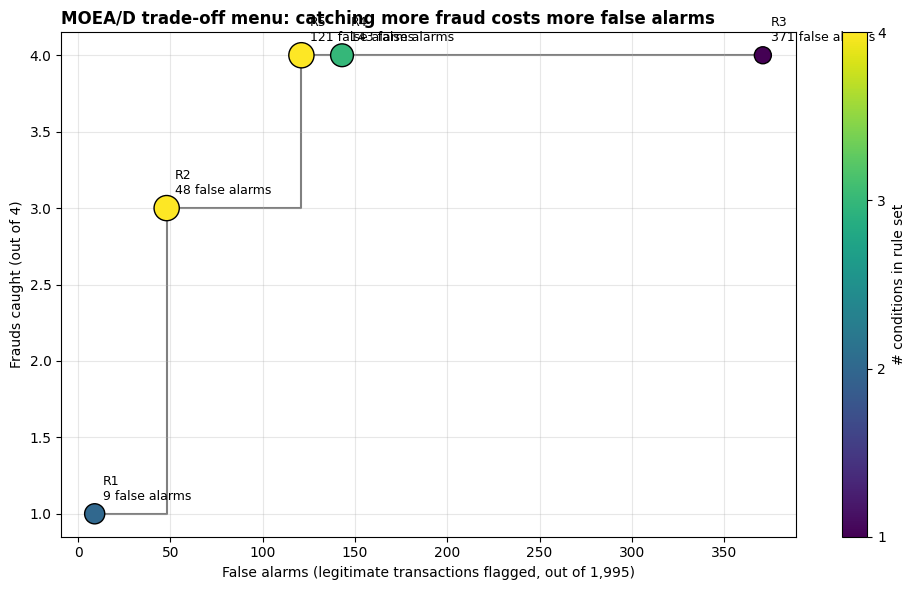

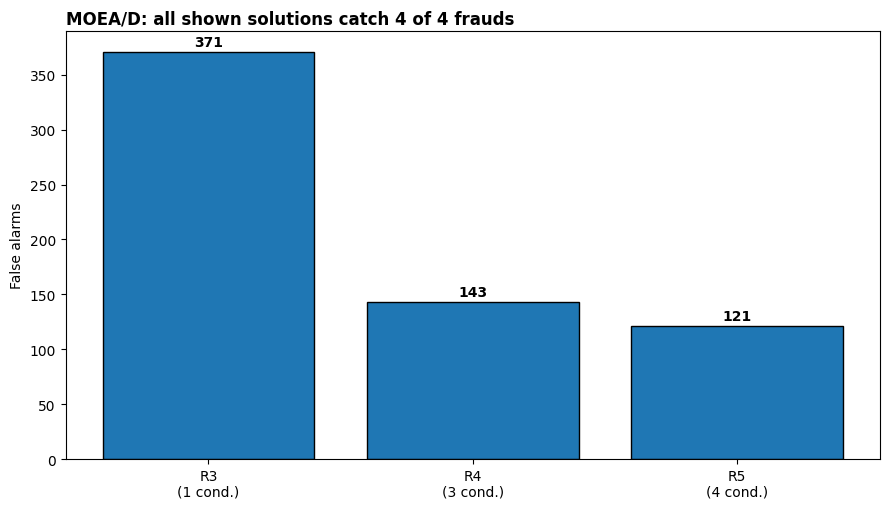

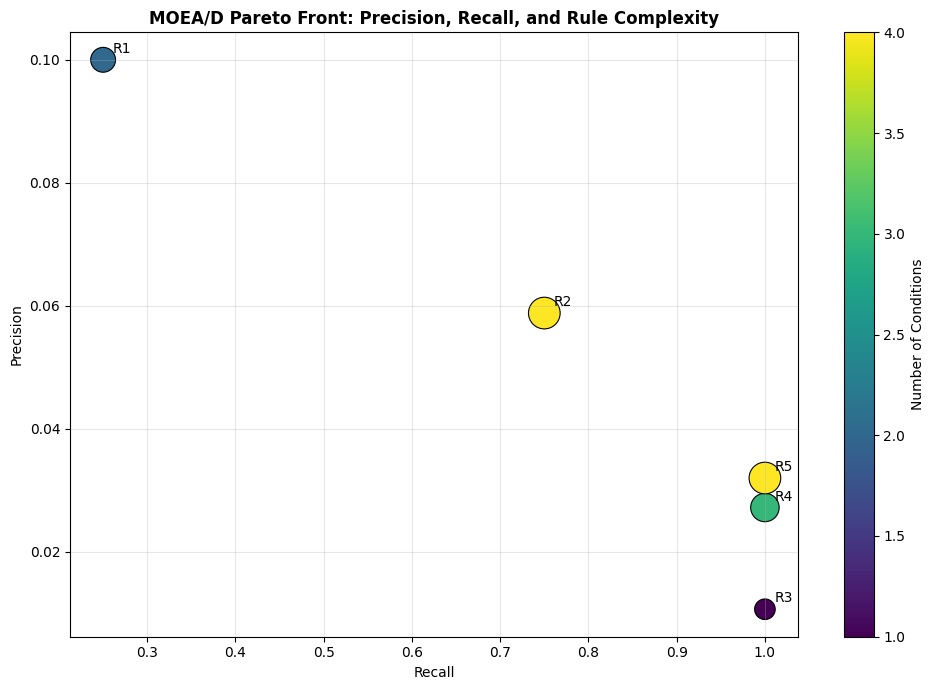

MOEA/D visuals saved to /content/outputs_synthetic/moead_visuals/


In [16]:
# ============================================================
# MOEA/D – PRESENTATION VISUALS
# Mirrors NSGA-II / SPEA2 outputs for direct comparison
# ============================================================

if RUN_MOEAD and len(moead_pareto_df) > 0:

    _VIS = f"{OUTPUT_DIR}/moead_visuals"
    os.makedirs(_VIS, exist_ok=True)

    _n_rows  = len(X_val)
    _n_fraud = int(np.asarray(y_val).sum())

    vis = moead_pareto_df.copy().reset_index(drop=True)

    vis["ID"] = [f"R{i+1}" for i in range(len(vis))]
    vis["alerts"] = (vis["alert_rate"] * _n_rows).round().astype(int)
    vis["caught"] = (vis["recall"] * _n_fraud).round().astype(int)
    vis["false_alarms"] = vis["alerts"] - vis["caught"]

    # 1) Trade-off menu
    fig, ax = plt.subplots(figsize=(10, 6))

    f = vis.sort_values("false_alarms")

    ax.step(
        f["false_alarms"],
        f["caught"],
        where="post",
        color="grey",
        lw=1.5,
        zorder=1
    )

    sc = ax.scatter(
        f["false_alarms"],
        f["caught"],
        s=90 + 60 * f["total_conditions"],
        c=f["total_conditions"],
        cmap="viridis",
        edgecolors="black",
        zorder=3
    )

    for _, row in f.iterrows():
        ax.annotate(
            f"{row['ID']}\n{row['false_alarms']} false alarms",
            (row["false_alarms"], row["caught"]),
            xytext=(6, 10),
            textcoords="offset points",
            fontsize=9
        )

    ax.set_xlabel(
        f"False alarms (legitimate transactions flagged, out of {_n_rows - _n_fraud:,})"
    )
    ax.set_ylabel(f"Frauds caught (out of {_n_fraud})")
    ax.set_title(
        "MOEA/D trade-off menu: catching more fraud costs more false alarms",
        loc="left",
        fontweight="bold"
    )
    ax.grid(alpha=0.3)

    plt.colorbar(
        sc,
        ax=ax,
        ticks=sorted(vis["total_conditions"].unique())
    ).set_label("# conditions in rule set")

    fig.tight_layout()
    fig.savefig(
        f"{_VIS}/1_tradeoff_menu.png",
        dpi=170,
        bbox_inches="tight"
    )
    plt.show()

    # 2) Complexity vs false alarms among max-recall solutions
    top = (
        vis[vis["caught"] == vis["caught"].max()]
        .sort_values(["total_conditions", "false_alarms"])
    )

    if len(top) >= 2:

        fig, ax = plt.subplots(figsize=(9, 5.2))

        labels = (
            top["ID"]
            + "\n("
            + top["total_conditions"].astype(str)
            + " cond.)"
        )

        bars = ax.bar(
            labels,
            top["false_alarms"],
            edgecolor="black"
        )

        for bar, value in zip(bars, top["false_alarms"]):
            ax.text(
                bar.get_x() + bar.get_width()/2,
                value + max(top["false_alarms"]) * 0.015,
                f"{value}",
                ha="center",
                fontweight="bold"
            )

        ax.set_ylabel("False alarms")
        ax.set_title(
            f"MOEA/D: all shown solutions catch {int(vis['caught'].max())} "
            f"of {_n_fraud} frauds",
            loc="left",
            fontweight="bold"
        )

        fig.tight_layout()
        fig.savefig(
            f"{_VIS}/2_complexity_pays_off.png",
            dpi=170,
            bbox_inches="tight"
        )
        plt.show()

    # 3) Simple Precision / Recall / Complexity Pareto view
    fig, ax = plt.subplots(figsize=(10, 7))

    scatter = ax.scatter(
        vis["recall"],
        vis["precision"],
        s=120 + vis["total_conditions"] * 100,
        c=vis["total_conditions"],
        cmap="viridis",
        edgecolors="black",
        linewidths=0.8
    )

    for _, row in vis.iterrows():
        ax.annotate(
            row["ID"],
            (row["recall"], row["precision"]),
            xytext=(7, 5),
            textcoords="offset points",
            fontsize=10
        )

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(
        "MOEA/D Pareto Front: Precision, Recall, and Rule Complexity",
        fontweight="bold"
    )
    ax.grid(alpha=0.3)

    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Number of Conditions")

    fig.tight_layout()
    fig.savefig(
        f"{_VIS}/3_pareto_front.png",
        dpi=170,
        bbox_inches="tight"
    )
    plt.show()

    vis[
        [
            "ID",
            "caught",
            "alerts",
            "false_alarms",
            "total_conditions",
            "rule_set_string"
        ]
    ].to_csv(
        f"{_VIS}/rule_set_counts.csv",
        index=False
    )

    print(f"MOEA/D visuals saved to {_VIS}/")


In [ ]:
if RUN_NSGA2 and RUN_COEVOLUTION:

    # ── Pre-compute coevo HOF points for plotting ──────────────────────
    co_hof_rows = []
    for rs in list(rs_hof):
        vp = apply_ruleset(rs, X_val)
        m  = evaluate_metrics(y_val, vp)
        co_hof_rows.append(m)
    co_hof_df = pd.DataFrame(co_hof_rows)

    _op_markers = {"conservative": "^", "balanced": "s", "aggressive": "v"}
    _op_colors  = {"conservative": "#003f88", "balanced": "#007744", "aggressive": "#8800cc"}
    _op_names   = ["conservative", "balanced", "aggressive"]

    fig = plt.figure(figsize=(20, 10))
    gs  = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.3)

    # ── Panel 1 (top-left): Precision vs Recall Pareto front ──────────────
    ax1 = fig.add_subplot(gs[0, 0])
    n2_sorted = nsga2_pareto_df.sort_values("recall")
    ax1.scatter(n2_sorted["recall"], n2_sorted["precision"],
                c="steelblue", s=50, alpha=0.7, zorder=3, label="NSGA-II front")
    ax1.step(n2_sorted["recall"].tolist(), n2_sorted["precision"].tolist(),
             where="post", color="steelblue", linewidth=1.5, alpha=0.5)
    ax1.scatter(co_hof_df["recall"], co_hof_df["precision"],
                c="darkorange", marker="*", s=250, alpha=0.9, zorder=4, label="Coevo HOF")
    if RUN_BASELINE_GA:
        vp_b = apply_path(best_baseline_rule, X_val).astype(int)
        bm   = evaluate_metrics(y_val, vp_b)
        ax1.scatter(bm["recall"], bm["precision"],
                    c="red", marker="D", s=130, zorder=5, label="Baseline GA")
    for name in _op_names:
        if name in nsga2_ops:
            r = nsga2_ops[name]
            ax1.scatter(r["recall"], r["precision"],
                        marker=_op_markers[name], c=_op_colors[name],
                        s=180, edgecolors="black", linewidths=1.5, zorder=6,
                        label=f"NSGA-II {name}")
        if name in operating_points:
            r = operating_points[name]
            ax1.scatter(r["recall"], r["precision"],
                        marker=_op_markers[name], c=_op_colors[name],
                        s=180, edgecolors="white", linewidths=2.0, zorder=6,
                        label=f"Coevo {name}")
    ax1.set_xlabel("Recall"); ax1.set_ylabel("Precision")
    ax1.set_title("Precision–Recall Pareto Front (Val)  [●=NSGA-II op, ○=Coevo op]")
    ax1.legend(fontsize=7, loc="upper right", ncol=2); ax1.grid(True, alpha=0.3)

    # ── Panel 2 (top-right): Alert Rate vs F1 ────────────────────────
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.scatter(nsga2_pareto_df["alert_rate"], nsga2_pareto_df["f1"],
                c="steelblue", s=50, alpha=0.7, label="NSGA-II front")
    ax2.scatter(co_hof_df["alert_rate"], co_hof_df["f1"],
                c="darkorange", marker="*", s=250, alpha=0.9, label="Coevo HOF")
    if RUN_BASELINE_GA:
        ax2.scatter(bm["alert_rate"], bm["f1"],
                    c="red", marker="D", s=130, label="Baseline GA")
    ax2.axvline(ALPHA, color="gray", linestyle="--", alpha=0.5,
                label=f"Alpha cap ({ALPHA})")
    ax2.set_xlabel("Alert Rate"); ax2.set_ylabel("Val F1")
    ax2.set_title("Alert Rate vs F1 (Val)")
    ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

    # ── Panel 3 (bottom-left): Convergence comparison ───────────────────
    ax3 = fig.add_subplot(gs[1, 0])
    ax3b = ax3.twiny()
    # Coevo: F1 over cycles (bottom x-axis)
    ax3.plot(coevo_history["cycle"], coevo_history["best_rs_f1"],
             color="darkorange", marker="s", markersize=4, label="Coevo best RS F1")
    ax3.plot(coevo_history["cycle"], coevo_history["best_path_f1"],
             color="orange", linestyle="--", alpha=0.7, label="Coevo best path F1")
    ax3.set_xlabel("Coevolution cycle", color="darkorange")
    ax3.tick_params(axis="x", colors="darkorange")
    ax3.set_ylabel("F1 / Hypervolume")
    # NSGA-II: best F1 + normalised HV over gens (top x-axis)
    _hv_max = nsga2_history["hypervolume"].max()
    _hv_norm = nsga2_history["hypervolume"] / (_hv_max + 1e-12)
    ax3b.plot(nsga2_history["gen"], nsga2_history["best_f1"],
              color="steelblue", marker="o", markersize=3, label="NSGA-II best F1")
    ax3b.plot(nsga2_history["gen"], _hv_norm,
              color="skyblue", linestyle=":", alpha=0.8, label="NSGA-II HV (norm.)")
    ax3b.set_xlabel("NSGA-II generation", color="steelblue")
    ax3b.tick_params(axis="x", colors="steelblue")
    lines1, labs1 = ax3.get_legend_handles_labels()
    lines2, labs2 = ax3b.get_legend_handles_labels()
    ax3.legend(lines1 + lines2, labs1 + labs2, fontsize=7, loc="lower right")
    ax3.set_title("Convergence: Coevolution vs NSGA-II")
    ax3.grid(True, alpha=0.3)

    # ── Panel 4 (bottom-right): Operating point bar chart (Test Set) ───────
    ax4 = fig.add_subplot(gs[1, 1])
    op_rows = []
    for name in _op_names:
        if name in test_op_results:
            m = test_op_results[name]
            op_rows.append({"label": f"Coevo-{name[:4]}",
                            "Precision": m["precision"], "Recall": m["recall"],
                            "F1": m["f1"], "color": "darkorange"})
        if name in nsga2_test_op_res:
            m = nsga2_test_op_res[name]
            op_rows.append({"label": f"NSGA2-{name[:4]}",
                            "Precision": m["precision"], "Recall": m["recall"],
                            "F1": m["f1"], "color": "steelblue"})
    if RUN_BASELINE_GA:
        op_rows.insert(0, {
            "label": "Baseline",
            "Precision": baseline_test_metrics["precision"],
            "Recall":    baseline_test_metrics["recall"],
            "F1":        baseline_test_metrics["f1"],
            "color":     "red",
        })
    _metrics = ["Precision", "Recall", "F1"]
    _x       = np.arange(len(_metrics))
    _w       = 0.8 / len(op_rows)
    for i, row in enumerate(op_rows):
        ax4.bar(_x + i * _w, [row[m] for m in _metrics], _w,
                label=row["label"], color=row["color"], alpha=0.82)
    ax4.set_xticks(_x + _w * (len(op_rows) - 1) / 2)
    ax4.set_xticklabels(_metrics)
    ax4.set_ylabel("Score"); ax4.set_title("Operating Points — Test Set")
    ax4.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7)
    ax4.grid(True, alpha=0.3, axis="y")

    fig.suptitle("NSGA-II vs Coevolution GA — Full Comparison",
                 fontsize=13, fontweight="bold")
    fig.savefig(f"{OUTPUT_DIR}/nsga2_vs_coevo.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved to {OUTPUT_DIR}/nsga2_vs_coevo.png")

    # ── Comparison table ───────────────────────────────────────────────────────
    comp_rows = []
    if RUN_BASELINE_GA:
        comp_rows.append({
            "Method": "Baseline GA",
            "Precision": baseline_test_metrics["precision"],
            "Recall":    baseline_test_metrics["recall"],
            "F1":        baseline_test_metrics["f1"],
            "Alert":     baseline_test_metrics["alert_rate"],
            "# Rules": 1, "# Conds": len(best_baseline_rule),
        })
    for name in _op_names:
        if name in test_op_results:
            m = test_op_results[name]
            r = operating_points[name]
            comp_rows.append({
                "Method": f"Coevo-{name}",
                "Precision": m["precision"], "Recall": m["recall"],
                "F1": m["f1"], "Alert": m["alert_rate"],
                "# Rules": int(r["n_rules"]), "# Conds": int(r["total_conditions"]),
            })
        if name in nsga2_test_op_res:
            m = nsga2_test_op_res[name]
            r = nsga2_ops[name]
            comp_rows.append({
                "Method": f"NSGA-II-{name}",
                "Precision": m["precision"], "Recall": m["recall"],
                "F1": m["f1"], "Alert": m["alert_rate"],
                "# Rules": int(r["n_rules"]), "# Conds": int(r["total_conditions"]),
            })
    comp_df = pd.DataFrame(comp_rows).round(4)
    comp_df.to_csv(f"{OUTPUT_DIR}/nsga2_vs_coevo_comparison.csv", index=False)
    print("\nFull Method Comparison (Test Set):")
    print("=" * 85)
    print(comp_df.to_string(index=False))


---
## Section 8: Greedy Rule-Set Builder (Marginal Contribution)

### Algorithm
```
S <- empty
Precompute fires[p] for every candidate path p on the validation set

Repeat:
    For each remaining path p:
        score(p|S) = NewTP(p|S) - GREEDY_LAMBDA*NewFP(p|S) - GREEDY_GAMMA*Complexity(p)
    p* = argmax score(p|S)

    if NewTP(p*|S) < GREEDY_MIN_NEW_TP:  STOP  (diminishing returns)
    if len(S) >= GREEDY_MAX_RULES:        STOP  (parsimony cap)
    S <- S union {p*}
```

**Candidate pool**: all unique paths from the co-evolution Hall-of-Fame (and path HoF).
**Fast**: fires_matrix precomputed once; all marginal TP/FP are pure numpy boolean ops.
**Post-hoc assembly**: Greedy uses GA outputs as raw material — it is not an evolutionary algorithm.

In [ ]:
if not RUN_GREEDY:
    print("Skipping Greedy builder (RUN_GREEDY = False)")
elif not RUN_COEVOLUTION and not RUN_BASELINE_GA:
    print("Greedy builder requires at least one GA. Skipping.")
else:
    # -- Build candidate pool from coevo HoF (and path HoF) ------------------
    candidate_paths = []
    if RUN_COEVOLUTION:
        seen_keys = set()
        for rs in list(rs_hof):
            for p in rs:
                key = tuple(sorted(str(c) for c in p))
                if key not in seen_keys:
                    candidate_paths.append(list(p))
                    seen_keys.add(key)
        for p in list(path_hof):
            key = tuple(sorted(str(c) for c in p))
            if key not in seen_keys:
                candidate_paths.append(list(p))
                seen_keys.add(key)
    else:
        candidate_paths = [list(best_baseline_rule)]

    print(f"Candidate pool: {len(candidate_paths)} unique paths")

    # -- Precompute fires matrix on validation set ----------------------------
    n_val     = len(X_val)
    y_val_arr = np.asarray(y_val)
    fires_matrix = np.zeros((len(candidate_paths), n_val), dtype=bool)
    for i, path in enumerate(candidate_paths):
        fires_matrix[i] = apply_path(path, X_val)

    # -- Greedy loop ---------------------------------------------------------
    greedy_ruleset = []
    greedy_table   = []
    fires_S        = np.zeros(n_val, dtype=bool)
    remaining_idx  = list(range(len(candidate_paths)))

    print("\nGreedy Rule-Set Construction (Validation Set):")
    print("=" * 80)

    for step in range(1, GREEDY_MAX_RULES + 1):
        best_score, best_idx, best_new_tp, best_new_fp = -np.inf, -1, 0, 0

        for idx in remaining_idx:
            sc, ntp, nfp = marginal_score(
                fires_matrix[idx], fires_S, y_val_arr,
                lam=GREEDY_LAMBDA, gam=GREEDY_GAMMA,
                complexity=len(candidate_paths[idx])
            )
            if sc > best_score:
                best_score, best_idx, best_new_tp, best_new_fp = sc, idx, ntp, nfp

        if best_idx == -1 or best_new_tp < GREEDY_MIN_NEW_TP:
            print(f"  Stopped at step {step}: "
                  f"best NewTP={best_new_tp} < threshold {GREEDY_MIN_NEW_TP}")
            break

        chosen = candidate_paths[best_idx]
        greedy_ruleset.append(chosen)
        fires_S |= fires_matrix[best_idx]
        remaining_idx.remove(best_idx)

        cum_pred   = fires_S.astype(int)
        cum_prec   = precision_score(y_val_arr, cum_pred, zero_division=0)
        cum_recall = recall_score(y_val_arr, cum_pred, zero_division=0)
        cum_f1     = f1_score(y_val_arr, cum_pred, zero_division=0)
        cum_alert  = float(cum_pred.sum()) / n_val

        greedy_table.append({
            "Rule #":            step,
            "NewTP":             best_new_tp,
            "NewFP":             best_new_fp,
            "Marginal Score":    round(best_score, 3),
            "Cumul. Recall":     round(cum_recall, 4),
            "Cumul. Precision":  round(cum_prec, 4),
            "Cumul. F1":         round(cum_f1, 4),
            "Cumul. Alert Rate": round(cum_alert, 6),
            "Rule String":       pretty_path(chosen),
        })

        print(f"  Rule {step}: NewTP={best_new_tp:4d}  NewFP={best_new_fp:4d}  "
              f"Score={best_score:7.2f}  CumulF1={cum_f1:.4f}  Alert={cum_alert:.6f}")
        print(f"    -> {pretty_path(chosen)}")

    # -- Evaluate on all three splits ----------------------------------------
    greedy_table_df      = pd.DataFrame(greedy_table)
    greedy_test_pred     = apply_ruleset(greedy_ruleset, X_test)
    greedy_test_metrics  = evaluate_metrics(y_test, greedy_test_pred)
    greedy_val_pred      = fires_S.astype(int)
    greedy_val_metrics   = evaluate_metrics(y_val, greedy_val_pred)
    greedy_train_pred    = apply_ruleset(greedy_ruleset, X_train)
    greedy_train_metrics = evaluate_metrics(y_train, greedy_train_pred)

    print("\n" + "=" * 80)
    print("GREEDY RULE SET -- Final")
    print("=" * 80)
    print(pretty_ruleset(greedy_ruleset))
    print(f"  Rules: {len(greedy_ruleset)} | Conditions per rule: {[len(p) for p in greedy_ruleset]}")
    print(f"  Val  -> Prec: {greedy_val_metrics['precision']:.4f}  "
          f"Rec: {greedy_val_metrics['recall']:.4f}  F1: {greedy_val_metrics['f1']:.4f}")
    print(f"  Test -> Prec: {greedy_test_metrics['precision']:.4f}  "
          f"Rec: {greedy_test_metrics['recall']:.4f}  F1: {greedy_test_metrics['f1']:.4f}")
    print("\nGreedy addition table (validation set):")
    print(greedy_table_df.to_string(index=False))

    greedy_table_df.to_csv(f"{OUTPUT_DIR}/greedy_ruleset_table.csv", index=False)

    if greedy_table_df.empty:
        print("Greedy builder selected no rules -- nothing to plot.")
    else:
        # -- Plot ----------------------------------------------------------------
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        steps = greedy_table_df["Rule #"].values
        axes[0].plot(steps, greedy_table_df["Cumul. Precision"], "o-", label="Precision")
        axes[0].plot(steps, greedy_table_df["Cumul. Recall"],    "s-", label="Recall")
        axes[0].plot(steps, greedy_table_df["Cumul. F1"],        "^-", label="F1")
        axes[0].set_xlabel("Rule-set size"); axes[0].set_ylabel("Score")
        axes[0].set_title("Greedy Builder: Precision / Recall / F1 vs Rule-Set Size")
        axes[0].legend(); axes[0].grid(True, alpha=0.3)

        bar_x = np.arange(len(steps))
        axes[1].bar(bar_x - 0.2, greedy_table_df["NewTP"], 0.35,
                    label="New TP (fraud caught)", color="steelblue")
        axes[1].bar(bar_x + 0.2, greedy_table_df["NewFP"], 0.35,
                    label="New FP (false alarms)", color="tomato")
        axes[1].set_xticks(bar_x)
        axes[1].set_xticklabels([f"Rule {i}" for i in steps], rotation=30, ha="right")
        axes[1].set_ylabel("Count"); axes[1].set_title("Marginal TP vs FP per Rule Added")
        axes[1].legend(); axes[1].grid(True, alpha=0.3, axis="y")

        fig.tight_layout()
        fig.savefig(f"{OUTPUT_DIR}/greedy_builder.png", dpi=150)
        plt.show()
        print(f"Greedy table saved: {OUTPUT_DIR}/greedy_ruleset_table.csv")
        print(f"Greedy plot  saved: {OUTPUT_DIR}/greedy_builder.png")


---
## Section 8a: Greedy Builder — 30-Variant Hyperparameter Sweep

Sweeps a **5 × 6 grid** over two greedy knobs (GREEDY_MAX_RULES fixed at 10):

| Parameter | Values |
|---|---|
| `GREEDY_LAMBDA` | 0.1, 0.5, 1.0, 2.0, 5.0 |
| `GREEDY_GAMMA`  | 0.0, 0.25, 0.5, 1.0, 2.0, 5.0 |

Each variant reuses the **same coevolution Hall-of-Fame** (pre-computed `fires_matrix`)
from Section 8 — only the marginal-score weights change.
Results stored in `greedy_sweep_results` and saved by Section 13 (Export Results).

In [ ]:
import itertools

# -- Requires Section 8 to have run (candidate_paths + fires_matrix) ----------
_prereqs_ok = (
    RUN_GREEDY and
    "candidate_paths" in dir() and "fires_matrix" in dir()
)

if not _prereqs_ok:
    print("Section 8a requires RUN_GREEDY=True and Section 8 to have run. Skipping.")
else:
    SWEEP_LAMBDAS = [0.1, 0.5, 1.0, 2.0, 5.0]
    SWEEP_GAMMAS  = [0.0, 0.25, 0.5, 1.0, 2.0, 5.0]
    variants = list(itertools.product(SWEEP_LAMBDAS, SWEEP_GAMMAS))
    print(f"Running {len(variants)} greedy variants (GREEDY_MAX_RULES={GREEDY_MAX_RULES} fixed)...")

    y_val_sw   = np.asarray(y_val)
    y_train_sw = np.asarray(y_train)
    y_test_sw  = np.asarray(y_test)

    greedy_sweep_results = []

    for lam, gam in variants:
        vname = f"lam{lam}_gam{gam}"

        fires_S_v   = np.zeros(len(X_val), dtype=bool)
        remaining_v = list(range(len(candidate_paths)))
        greedy_rs_v = []

        for _ in range(GREEDY_MAX_RULES):
            best_sc, best_idx_v, best_ntp = -np.inf, -1, 0
            for idx in remaining_v:
                sc, ntp, _ = marginal_score(
                    fires_matrix[idx], fires_S_v, y_val_sw,
                    lam=lam, gam=gam,
                    complexity=len(candidate_paths[idx])
                )
                if sc > best_sc:
                    best_sc, best_idx_v, best_ntp = sc, idx, ntp

            if best_idx_v == -1 or best_ntp < GREEDY_MIN_NEW_TP:
                break

            greedy_rs_v.append(candidate_paths[best_idx_v])
            fires_S_v |= fires_matrix[best_idx_v]
            remaining_v.remove(best_idx_v)

        if not greedy_rs_v:
            print(f"  {vname}: no rules selected -- skipping")
            continue

        def _eval_sw(rs, X, y):
            return evaluate_metrics(y, apply_ruleset(rs, X))

        m_tr = _eval_sw(greedy_rs_v, X_train, y_train_sw)
        m_va = _eval_sw(greedy_rs_v, X_val,   y_val_sw)
        m_te = _eval_sw(greedy_rs_v, X_test,  y_test_sw)

        n_r = len(greedy_rs_v)
        n_c = sum(len(p) for p in greedy_rs_v)
        print(f"  {vname:25s} | rules={n_r} conds={n_c:2d} "
              f"| val_F1={m_va['f1']:.4f}  test_F1={m_te['f1']:.4f}")

        greedy_sweep_results.append({
            "model":             "Greedy Builder",
            "variant":           vname,
            "crossover":         None,
            "mutation":          None,
            "selection":         None,
            "coverage_lambda":   lam,
            "parsimony_mu":      gam,
            "pop_size":          None,
            "cx_prob":           None,
            "max_budget":        GREEDY_MAX_RULES,
            "converged_at":      n_r,
            "n_paths":           n_r,
            "total_conditions":  n_c,
            "train_precision":   m_tr["precision"],
            "train_recall":      m_tr["recall"],
            "train_f1":          m_tr["f1"],
            "train_alert_rate":  m_tr["alert_rate"],
            "val_precision":     m_va["precision"],
            "val_recall":        m_va["recall"],
            "val_f1":            m_va["f1"],
            "val_alert_rate":    m_va["alert_rate"],
            "test_precision":    m_te["precision"],
            "test_recall":       m_te["recall"],
            "test_f1":           m_te["f1"],
            "test_alert_rate":   m_te["alert_rate"],
            "best_rule_str":    pretty_ruleset(greedy_rs_v),
        })

    print(f"\nGreedy sweep complete: {len(greedy_sweep_results)} variants collected.")
    if greedy_sweep_results:
        _best = max(greedy_sweep_results, key=lambda r: r["test_f1"])
        print(f"Best variant (test F1={_best['test_f1']:.4f}): {_best['variant']}")

---
## Section 9: Multi-Seed Stability Analysis

Run the coevolution GA across 5 seeds to validate that results are reproducible.


In [ ]:
if not RUN_STABILITY:
    print("Skipping stability analysis (RUN_STABILITY = False)")
elif not RUN_COEVOLUTION:
    print("Skipping stability analysis (requires RUN_COEVOLUTION = True)")
else:
    print(f"Running stability analysis across seeds: {STABILITY_SEEDS}")
    print("=" * 60)
    stability_results = {}
    for seed in STABILITY_SEEDS:
        print(f"\nSeed {seed}:")
        _, best_rs_seed, _, _, rs_hof_seed = run_coevolution(seed=seed)
        seed_pareto_rows = []
        for rs in list(rs_hof_seed):
            vp = apply_ruleset(rs, X_val)
            m  = evaluate_metrics(y_val, vp)
            seed_pareto_rows.append({
                "precision": m["precision"], "recall": m["recall"],
                "f1": m["f1"], "alert_rate": m["alert_rate"],
                "n_rules": len(rs), "total_conditions": sum(len(p) for p in rs),
                "rule_set_string": pretty_ruleset(rs), "ruleset_obj": rs,
            })
        seed_pareto = pd.DataFrame(seed_pareto_rows)
        seed_ops    = select_operating_points(seed_pareto)
        for name, row in seed_ops.items():
            rs = row["ruleset_obj"]
            tp = apply_ruleset(rs, X_test)
            m  = evaluate_metrics(y_test, tp)
            stability_results.setdefault(name, []).append(
                {"seed": seed, **{k: v for k, v in m.items() if k in
                                   ["precision", "recall", "f1", "alert_rate"]}}
            )
    print("\n" + "=" * 70)
    print("STABILITY SUMMARY (TEST metrics across 5 seeds)")
    print("=" * 70)
    stab_rows = []
    for name, records in stability_results.items():
        df_s = pd.DataFrame(records)
        row  = {"operating_point": name, "n_seeds": len(df_s)}
        for metric in ["precision", "recall", "f1", "alert_rate"]:
            row[f"{metric}_mean"] = df_s[metric].mean()
            row[f"{metric}_std"]  = df_s[metric].std()
        stab_rows.append(row)
        print(f"\n[{name.upper()}]")
        print(f"  Precision: {row['precision_mean']:.4f} +/- {row['precision_std']:.4f}")
        print(f"  Recall:    {row['recall_mean']:.4f} +/- {row['recall_std']:.4f}")
        print(f"  F1:        {row['f1_mean']:.4f} +/- {row['f1_std']:.4f}")
        print(f"  Alert:     {row['alert_rate_mean']:.4f} +/- {row['alert_rate_std']:.4f}")
    stability_df = pd.DataFrame(stab_rows)
    stability_df.to_csv(f"{OUTPUT_DIR}/stability_metrics.csv", index=False)
    print(f"\nStability metrics saved to {OUTPUT_DIR}/stability_metrics.csv")


---
## Section 10: Pareto Front Visualizations


In [ ]:
if RUN_COEVOLUTION:
    df_plot = pd.read_csv(f"{OUTPUT_DIR}/pareto_front.csv")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sc = axes[0].scatter(
        df_plot["recall"], df_plot["precision"],
        c=df_plot["alert_rate"], s=20 + 5 * df_plot["total_conditions"],
        cmap="viridis", alpha=0.8, edgecolors="k", linewidths=0.3
    )
    plt.colorbar(sc, ax=axes[0]).set_label("Alert rate")
    axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
    axes[0].set_title("Pareto Front: Recall vs Precision")
    axes[0].grid(True, alpha=0.3)
    axes[1].scatter(df_plot["alert_rate"], df_plot["precision"],
        s=20 + 5 * df_plot["total_conditions"], alpha=0.8, edgecolors="k", linewidths=0.3)
    axes[1].set_xlabel("Alert rate"); axes[1].set_ylabel("Precision")
    axes[1].set_title("Alert Rate vs Precision")
    axes[1].grid(True, alpha=0.3)
    axes[2].scatter(df_plot["alert_rate"], df_plot["recall"],
        s=20 + 5 * df_plot["total_conditions"], alpha=0.8, edgecolors="k", linewidths=0.3)
    axes[2].set_xlabel("Alert rate"); axes[2].set_ylabel("Recall")
    axes[2].set_title("Alert Rate vs Recall")
    axes[2].grid(True, alpha=0.3)
    suffix = f"({SPLIT_MODE}, {'no-Time' if EXCLUDE_TIME_FEATURES else 'with-Time'}, synthetic)"
    fig.suptitle(f"Pareto Front Analysis {suffix}", fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/pareto_plots.png", dpi=150)
    plt.show()


---
## Section 11: Baseline vs Coevolution Comparison


In [ ]:
if RUN_BASELINE_GA and RUN_COEVOLUTION:
    print("METHOD COMPARISON (Test Set)")
    print("=" * 70)
    comp_data = [
        {"Method": "Baseline GA (single rule)",
         "Precision": baseline_test_metrics["precision"],
         "Recall":    baseline_test_metrics["recall"],
         "F1":        baseline_test_metrics["f1"],
         "Alert Rate":baseline_test_metrics["alert_rate"],
         "# Rules":   1,
         "# Conditions": len(best_baseline_rule)},
        {"Method": "Coevolution GA (best rule set)",
         "Precision": co_test_metrics["precision"],
         "Recall":    co_test_metrics["recall"],
         "F1":        co_test_metrics["f1"],
         "Alert Rate":co_test_metrics["alert_rate"],
         "# Rules":   len(best_ruleset),
         "# Conditions": sum(len(p) for p in best_ruleset)},
    ]
    for name, row in test_op_results.items():
        op_row = operating_points[name]
        comp_data.append({
            "Method": f"Coevolution -- {name}",
            "Precision": row["precision"], "Recall": row["recall"],
            "F1": row["f1"], "Alert Rate": row["alert_rate"],
            "# Rules": int(op_row["n_rules"]),
            "# Conditions": int(op_row["total_conditions"]),
        })
    # -- NSGA-II rows --
    if RUN_NSGA2:
        for name in ["conservative", "balanced", "aggressive"]:
            if name in nsga2_test_op_res:
                m   = nsga2_test_op_res[name]
                row = nsga2_ops[name]
                comp_data.append({
                    "Method":      f"NSGA-II -- {name}",
                    "Precision":   m["precision"],
                    "Recall":      m["recall"],
                    "F1":          m["f1"],
                    "Alert Rate":  m["alert_rate"],
                    "# Rules":     int(row["n_rules"]),
                    "# Conditions": int(row["total_conditions"]),
                })
    # -- Greedy Builder row --
    if RUN_GREEDY and "greedy_test_metrics" in dir():
        comp_data.append({
            "Method":      "Greedy Builder",
            "Precision":   greedy_test_metrics["precision"],
            "Recall":      greedy_test_metrics["recall"],
            "F1":          greedy_test_metrics["f1"],
            "Alert Rate":  greedy_test_metrics["alert_rate"],
            "# Rules":     len(greedy_ruleset),
            "# Conditions": sum(len(p) for p in greedy_ruleset),
        })

    comp_df = pd.DataFrame(comp_data).round(4)
    comp_df.to_csv(f"{OUTPUT_DIR}/method_comparison.csv", index=False)
    print(comp_df.to_string(index=False))
    metrics_to_plot = ["Precision", "Recall", "F1"]
    x     = np.arange(len(metrics_to_plot))
    width = 0.8 / len(comp_df)
    fig, ax = plt.subplots(figsize=(12, 5))
    for i, (_, row) in enumerate(comp_df.iterrows()):
        ax.bar(x + i * width, [row[m] for m in metrics_to_plot], width, label=row["Method"], alpha=0.85)
    ax.set_xticks(x + width * (len(comp_df) - 1) / 2)
    ax.set_xticklabels(metrics_to_plot)
    ax.set_ylabel("Score")
    ax.set_title(f"Method Comparison -- Test Set ({SPLIT_MODE} split, synthetic data)")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3, axis="y")
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/method_comparison.png", dpi=150)
    plt.show()

---
## Section 12: No-Time Leak Verification

Confirm that the simulated `Time` column does not appear in any evolved rule.


In [ ]:
if EXCLUDE_TIME_FEATURES and (RUN_COEVOLUTION or RUN_NSGA2):
    patterns   = {f: re.compile(r"\b" + re.escape(f) + r"\b") for f in TIME_FEATURES}
    leak_found = False
    all_rule_strings = []
    if RUN_COEVOLUTION and "pareto_df" in dir():
        all_rule_strings += pareto_df["rule_set_string"].tolist()
    if RUN_NSGA2 and "nsga2_pareto_df" in dir():
        all_rule_strings += nsga2_pareto_df["rule_set_string"].tolist()
    for rule_str in all_rule_strings:
        for feat, pat in patterns.items():
            if pat.search(rule_str):
                print(f"LEAK DETECTED: '{feat}' found in rule: {rule_str}")
                leak_found = True
    if not leak_found:
        print(f"PASS: No Time features found in any of {len(all_rule_strings)} evolved rule sets.")
else:
    print("Leak check skipped (Time features not excluded or no rule-set model run).")


---
## Section 13: Export Results


In [ ]:
results_summary = {
    "config": {
        "dataset":               DATA_FILE,
        "split_mode":            SPLIT_MODE,
        "exclude_time_features": EXCLUDE_TIME_FEATURES,
        "top_k_features":        TOP_K,
        "top_features":          TOP_FEATURES,
        "random_seed":           RANDOM_SEED,
        "stability_seeds":       STABILITY_SEEDS,
        "categorical_columns":   CAT_COLS,
        "binned_feature":        BIN_FEATURE_OUT,
        "feature_mode":          FEATURE_MODE,
        "n_sample":              int(len(df)),
        "max_total_conditions":  MAX_TOTAL_CONDITIONS,
        "hv_ref_point":          HV_REF_POINT,
    }
}

if RUN_BASELINE_GA:
    results_summary["baseline_ga"] = {
        "best_rule":    pretty_path(best_baseline_rule),
        "n_conditions": len(best_baseline_rule),
        "operators": {
            "crossover": "SwapCX",
            "mutation":  "ThresholdBiasedMut",
            "selection": "Tournament3",
        },
        "train_metrics": {k: float(v) for k, v in baseline_train_metrics.items()
                          if k not in ["TP","FP","FN","TN"]},
        "val_metrics":   {k: float(v) for k, v in baseline_val_metrics.items()
                          if k not in ["TP","FP","FN","TN"]},
        "test_metrics":  {k: float(v) for k, v in baseline_test_metrics.items()
                          if k not in ["TP","FP","FN","TN"]},
    }

if RUN_COEVOLUTION:
    results_summary["coevolution_ga"] = {
        "best_ruleset":   pretty_ruleset(best_ruleset),
        "n_paths":        len(best_ruleset),
        "nodes_per_path": [len(p) for p in best_ruleset],
        "operators": {
            "path_crossover":    "cx_paths_co (swap condition)",
            "path_mutation":     "mutate_path_co (thr/flip/replace/add_node/drop_node)",
            "ruleset_crossover": "cx_rulesets_co (swap path)",
            "ruleset_mutation":  "mutate_ruleset_co (add_path/drop_path/mutate_node)",
            "selection":         "Tournament3",
        },
        "train_metrics":  {k: float(v) for k, v in co_train_metrics.items()
                           if k not in ["TP","FP","FN","TN"]},
        "val_metrics":    {k: float(v) for k, v in co_val_metrics.items()
                           if k not in ["TP","FP","FN","TN"]},
        "test_metrics":   {k: float(v) for k, v in co_test_metrics.items()
                           if k not in ["TP","FP","FN","TN"]},
        "operating_points": {
            name: {k: float(v) for k, v in m.items() if k not in ["TP","FP","FN","TN"]}
            for name, m in test_op_results.items()
        }
    }

if RUN_NSGA2:
    results_summary["nsga2_ga"] = {
        "operators": {
            "crossover": "cx_rulesets_co (swap path) + repair",
            "mutation":  "mutate_ruleset_co (add_path/drop_path/mutate_node) + repair",
            "selection": "NSGA2 TournamentDCD + selNSGA2",
            "fitness":   "(Precision max, Recall max, #conditions min) 3-objective",
            "constraint": f"total conditions <= {MAX_TOTAL_CONDITIONS}",
        },
        "pareto_front_size": len(nsga2_pareto_df),
        "hypervolume_3d_val":  nsga2_val_hv,
        "hypervolume_3d_test": nsga2_test_hv,
        "operating_points": {
            name: {
                "train_metrics": {k: float(v) for k, v in nsga2_train_op_res[name].items()
                                  if k not in ["TP","FP","FN","TN"]},
                "val_metrics":   {k: float(v) for k, v in nsga2_ops[name].items()
                                  if k not in ["TP","FP","FN","TN","ruleset_obj",
                                               "n_rules","total_conditions","rule_set_string"]},
                "test_metrics":  {k: float(v) for k, v in nsga2_test_op_res[name].items()
                                  if k not in ["TP","FP","FN","TN"]},
            }
            for name in nsga2_test_op_res
        }
    }

if RUN_GREEDY and "greedy_test_metrics" in dir():
    results_summary["greedy_builder"] = {
        "best_ruleset":   pretty_ruleset(greedy_ruleset),
        "n_paths":        len(greedy_ruleset),
        "nodes_per_path": [len(p) for p in greedy_ruleset],
        "hyperparameters": {
            "lambda":    GREEDY_LAMBDA,
            "gamma":     GREEDY_GAMMA,
            "max_rules": GREEDY_MAX_RULES,
            "min_new_tp": GREEDY_MIN_NEW_TP,
        },
        "train_metrics": {k: float(v) for k, v in greedy_train_metrics.items()
                          if k not in ["TP","FP","FN","TN"]},
        "val_metrics":   {k: float(v) for k, v in greedy_val_metrics.items()
                          if k not in ["TP","FP","FN","TN"]},
        "test_metrics":  {k: float(v) for k, v in greedy_test_metrics.items()
                          if k not in ["TP","FP","FN","TN"]},
    }

output_path = f"{OUTPUT_DIR}/results_summary.json"
with open(output_path, "w") as f:
    json.dump(results_summary, f, indent=2)

print(f"Results summary saved to: {output_path}")
print(f"\nAll outputs in: {OUTPUT_DIR}/")
for fname in sorted(os.listdir(OUTPUT_DIR)):
    fpath = os.path.join(OUTPUT_DIR, fname)
    print(f"  {fname:<50s}  {os.path.getsize(fpath)/1024:.1f} KB")

In [ ]:

# ============================================================
# SAVE ALL MODEL RESULTS -> all_model_results.csv
# 105 Baseline GA grid + 30 Coevolution GA + 30 NSGA-II + 30 Greedy Builder = 195 rows
#
# Parameter columns (family-specific, NaN elsewhere):
#   Baseline GA    -> crossover, mutation, selection
#   Coevo GA       -> coverage_lambda, parsimony_mu
#   NSGA-II        -> pop_size, cx_prob
#   Greedy Builder -> coverage_lambda (lambda), parsimony_mu (gamma)
# Shared columns: max_budget, converged_at, n_paths, total_conditions
# ============================================================
_all_rows = []

# --- Baseline GA grid search (105 rows) ---
if RUN_BASELINE_GRID and RUN_BASELINE_GA and 'grid_results' in dir():
    for r in grid_results:
        _all_rows.append({
            "model":            "Baseline GA",
            "variant":          f"{r['cx']}_{r['mut']}_{r['sel']}",
            "crossover":        r["cx"],
            "mutation":         r["mut"],
            "selection":        r["sel"],
            "coverage_lambda":  None,
            "parsimony_mu":     None,
            "pop_size":         None,
            "cx_prob":          None,
            "max_budget":       None,
            "converged_at":     None,
            "n_paths":          None,
            "total_conditions": None,
            "train_precision":  r["train_precision"],
            "train_recall":     r["train_recall"],
            "train_f1":         r["train_f1"],
            "train_alert_rate": r["train_alert_rate"],
            "val_precision":    r["val_precision"],
            "val_recall":       r["val_recall"],
            "val_f1":           r["val_f1"],
            "val_alert_rate":   r["val_alert_rate"],
            "test_precision":   r["test_precision"],
            "test_recall":      r["test_recall"],
            "test_f1":          r["test_f1"],
            "test_alert_rate":  r["test_alert_rate"],
            "best_rule_str":   r.get("rule"),
        })

# --- Coevolution GA sweep (30 rows) ---
if RUN_COEVOLUTION and 'coevo_sweep_results' in dir():
    for r in coevo_sweep_results:
        _all_rows.append({
            **r,
            "crossover": None,
            "mutation":  None,
            "selection": None,
        })

# --- NSGA-II sweep (30 rows) ---
if RUN_NSGA2 and 'nsga2_sweep_results' in dir():
    for r in nsga2_sweep_results:
        _all_rows.append({
            **r,
            "crossover": None,
            "mutation":  None,
            "selection": None,
        })

# --- Greedy Builder sweep (30 rows) ---
if RUN_GREEDY and 'greedy_sweep_results' in dir():
    for r in greedy_sweep_results:
        _all_rows.append(r)

if _all_rows:
    _col_order = [
        "model", "variant",
        "crossover", "mutation", "selection",
        "coverage_lambda", "parsimony_mu",
        "pop_size", "cx_prob",
        "max_budget", "converged_at",
        "n_paths", "total_conditions",
        "train_precision", "train_recall", "train_f1", "train_alert_rate",
        "val_precision",   "val_recall",   "val_f1",   "val_alert_rate",
        "test_precision",  "test_recall",  "test_f1",  "test_alert_rate",
        "best_rule_str",
    ]
    all_model_results_df = pd.DataFrame(_all_rows)[_col_order]
    _out = f"{OUTPUT_DIR}/all_model_results.csv"
    all_model_results_df.to_csv(_out, index=False)

    counts = all_model_results_df["model"].value_counts()
    print(f"Saved {len(all_model_results_df)} rows -> {_out}")
    for m, c in counts.items():
        print(f"  {m}: {c} variants")
    print()
    print(all_model_results_df[["model","variant","converged_at","val_f1","test_f1"]].to_string(index=False))
else:
    print("No results found -- run the model cells above first.")